[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/07_diffusion_design_space.ipynb)

# 07 · The Diffusion Training Design Space: Schedule, Target, Weighting, Conditioning

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| **07** | **Diffusion design space** | **Denoise step by step; schedule, target, weighting** | **Quality and coverage together** | **Pixel space, MLP backbone, no text** |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

Notebook 06 ended with a wish list: stable training by regression, the coverage of a likelihood model, sharp
samples, and a sampling cost that does not grow with the number of pixels. Diffusion models
([Sohl-Dickstein et al., 2015](https://arxiv.org/abs/1503.03585), [Song & Ermon, 2019](https://arxiv.org/abs/1907.05600), [Ho et al., 2020](https://arxiv.org/abs/2006.11239)) meet it with one idea. Destroy an image gradually by adding
noise, and train a network to undo a little of the damage. Sampling starts from pure noise and applies the network
repeatedly.

The idea leaves many choices open, and the papers of 2020 to 2023 are mostly about those choices. This notebook
trains about thirty small denoisers and changes one choice at a time:

* the **noise schedule** (linear, cosine, zero terminal signal-to-noise ratio);
* the **target** the network predicts (the noise, the clean image, or the mixture called $v$);
* the **weight** of each noise level in the loss;
* how the network is told the **noise level**;
* the **moving average** of the weights;
* **label dropout** and classifier-free guidance;
* the **sampler** and the number of steps;
* the reformulation of all of these by [Karras et al., 2022](https://arxiv.org/abs/2206.00364) (EDM).

## Learning objectives

1. Write down the forward process and the denoising loss, and train and sample a diffusion model.
2. Convert between predictions of noise, clean image and $v$, and explain how the choice of target acts as a loss
   weight.
3. Read a noise schedule as a signal-to-noise curve, and explain what zero terminal SNR fixes.
4. Explain what the EMA of the weights, label dropout and the guidance scale each do, and measure them.
5. Recognise memorisation in a generative model trained on a small dataset.

**Runtime:** about 8 minutes on a laptop CPU (thirty denoisers of 13 to 50 seconds each).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from prelib import diffusion as D, generative as G, images, metrics, viz, set_seed, CKPT_DIR
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()             # 8x8 digits as vectors of 64 numbers in [-1, 1]
judge = images.get_judge()
card = metrics.ImageScorecard(judge, Xtr, Xte, yte)
N = len(Xte)
LABELS = ytr[torch.randperm(len(ytr), generator=torch.Generator().manual_seed(0))[:N]]     # the digits we ask for, with the frequencies of the training set
NO_LABEL = torch.full((N,), D.NULL)

ROWS, RUNS = {}, {}
COLS = ["fd", "precision", "coverage", "nn_ratio", "judge_acc", "nfe"]

def score(x, name, nfe, labels=None, keep=True):
    row = card.evaluate(x, name, nfe=nfe, labels=labels); card.rows.pop()
    row["contrast"] = G.contrast(x)
    if keep:
        ROWS[name] = row
    return row

def table(names, cols=COLS):
    return pd.DataFrame([ROWS[n] for n in names]).set_index("model").reindex(columns=cols).round({"fd": 1, "precision": 2, "coverage": 2, "nn_ratio": 2, "judge_acc": 2})

def run(name, diff=None, steps=3000, width=128, seed=0, time="sinusoidal", p_uncond=0.1, track=False, **kw):
    # Train one denoiser and keep it in RUNS[name]. track=True also measures the FD of its samples every 500 steps.
    diff = diff or D.Diffusion("cosine", "eps")
    set_seed(seed); model = D.Denoiser(width, 3, time=time); log = []
    def measure(step, raw, ema):
        log.append(dict(step=step, **{k: score(diff.sample(m, LABELS, steps=50), "in training", 50, keep=False)["fd"] for k, m in (("EMA weights", ema), ("last weights", raw))}))
    out = D.train(model, diff, Xtr, ytr, steps=steps, seed=seed, p_uncond=p_uncond, callback=measure if track else None, every=500, **kw)
    out.update(diff=diff, track=pd.DataFrame(log).set_index("step") if track else None, params=sum(p.numel() for p in model.parameters()))
    RUNS[name] = out
    return out

def sample(name, steps=50, w=0.0, labels=None, **kw):
    r = RUNS[name]
    return r["diff"].sample(r["model"], LABELS if labels is None else labels, steps=steps, w=w, **kw)

def report(name, row=None, steps=50, w=0.0, keep=True, **kw):
    # Sample from RUNS[name] with the requested labels and score the samples.
    return score(sample(name, steps=steps, w=w, **kw), row or name, nfe=steps * (2 if w else 1), labels=LABELS, keep=keep)

real = card.real_baseline(); card.rows.pop(); ROWS["real data"] = real
nb06 = metrics.load_scorecard(); nb06 = nb06[nb06.notebook == "06_image_generators"].set_index("model")[["fd", "precision", "coverage", "nn_ratio", "nfe"]]
print(f"{len(Xtr)} training images, {N} held-out images. The best models of notebook 06 (medians of three seeds):")
display(nb06.round(2))

1438 training images, 359 held-out images. The best models of notebook 06 (medians of three seeds):


,fd,precision,coverage,nn_ratio,nfe
model,,,,,
real data,5.35,0.96,0.96,1.02,0.0
"autoencoder, codes from N(0, 1)",179.63,0.54,0.18,0.99,1.0
"VAE, KL weight 1, median of 3 seeds",80.07,0.74,0.68,0.97,1.0
"VAE, KL weight 0.3, median of 3 seeds",55.33,0.79,0.74,0.96,1.0
"GAN, median of 3 seeds",56.24,0.63,0.31,1.01,1.0
"WGAN-GP, median of 3 seeds",13.84,0.72,0.47,0.99,1.0
"pixel autoregression, median of 3 seeds",14.56,0.82,0.72,0.98,64.0


## 1. The forward process: destroying an image in small steps

Take a clean image $x_0$ and add a little Gaussian noise, $T = 1000$ times. Because sums of Gaussians are Gaussian,
the result after $t$ steps can be written in one line:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1 - \bar\alpha_t}\,\epsilon, \qquad \epsilon \sim \mathcal{N}(0, I).$$

$\bar\alpha_t$ falls from almost 1 at $t = 0$ to almost 0 at $t = T$. It is the share of the variance of $x_t$ that
is still signal. The **noise schedule** is the choice of this curve, and it is usually described by the
**signal-to-noise ratio**

$$\text{SNR}(t) = \frac{\bar\alpha_t}{1 - \bar\alpha_t}.$$

Nothing is learned in the forward process. It only defines the training data for the network: pairs of a noisy
image and the clean image it came from, at every noise level.

Three schedules are in common use.

* **Linear** ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)): the variance added per step rises linearly from $10^{-4}$ to $0.02$.
* **Scaled linear**: the variant used by Stable Diffusion ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)), which stops with a little signal left.
* **Cosine** ([Nichol & Dhariwal, 2021](https://arxiv.org/abs/2102.09672)): $\bar\alpha_t$ follows a squared cosine, so that the image is destroyed more evenly
  over the steps.

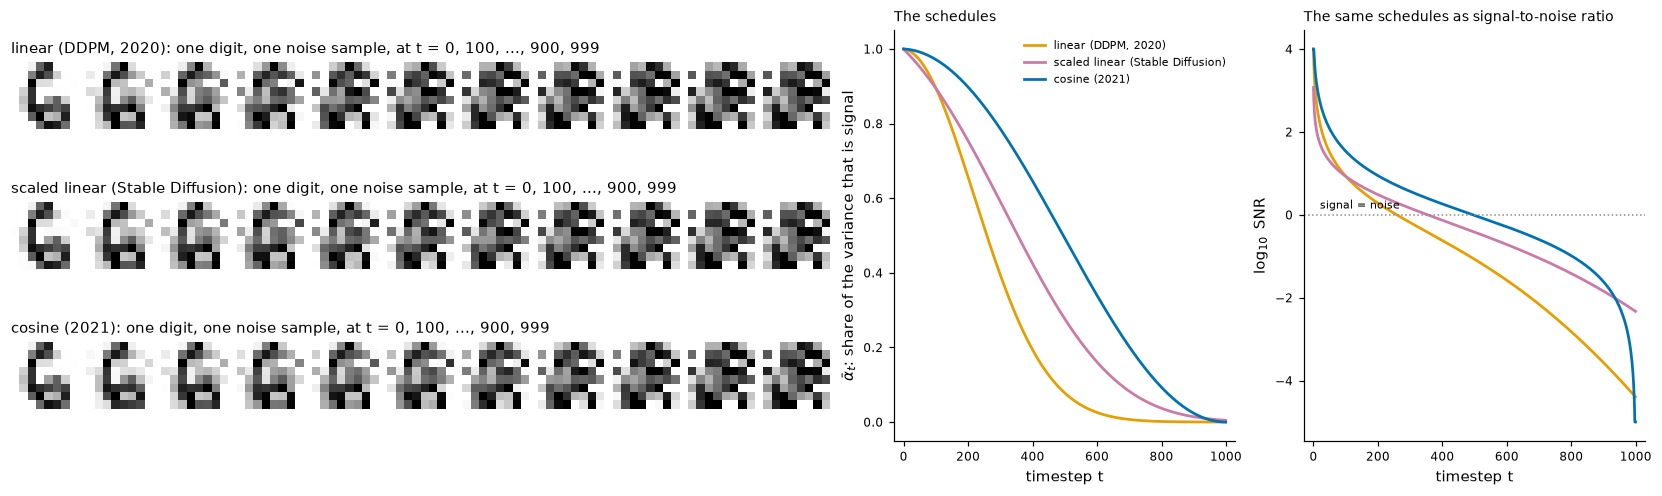

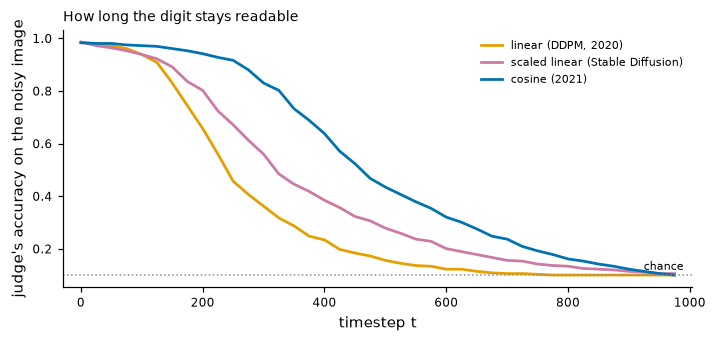

,last timestep at which the judge is right half the time,signal share at t = 500,SNR at the last timestep
"linear (DDPM, 2020)",225,0.078,0.000040
scaled linear (Stable Diffusion),300,0.276,0.004682
cosine (2021),450,0.492,0.000010


In [2]:
SCHEDULES = {"linear (DDPM, 2020)": "linear", "scaled linear (Stable Diffusion)": "sd-linear", "cosine (2021)": "cosine"}
abar = {k: D.alpha_bar(v) for k, v in SCHEDULES.items()}
colours = dict(zip(abar, [viz.ORANGE, viz.PINK, viz.BLUE]))
ts = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 999]
noise = torch.randn(Xte.shape, generator=torch.Generator().manual_seed(0))

fig = plt.figure(figsize=(15, 4.4))
gs = fig.add_gridspec(3, 3, width_ratios=[2.4, 1, 1])
for r, (name, ab) in enumerate(abar.items()):
    strip = torch.stack([ab[t].sqrt() * Xte[0] + (1 - ab[t]).sqrt() * noise[0] for t in ts])
    images.show_grid(strip, nrow=len(ts), ax=fig.add_subplot(gs[r, 0]), title=f"{name}: one digit, one noise sample, at t = 0, 100, ..., 900, 999")
ax = fig.add_subplot(gs[:, 1])
for name, ab in abar.items():
    ax.plot(ab, color=colours[name], label=name)
ax.set_xlabel("timestep t"); ax.set_ylabel(r"$\bar\alpha_t$: share of the variance that is signal"); ax.set_title("The schedules", fontsize=9); ax.legend(fontsize=7, loc="upper right")
ax = fig.add_subplot(gs[:, 2])
for name, ab in abar.items():
    ax.plot(torch.log10(ab / (1 - ab)), color=colours[name])
ax.axhline(0, color=viz.GREY, ls=":", lw=1); ax.text(20, 0.15, "signal = noise", fontsize=7)
ax.set_xlabel("timestep t"); ax.set_ylabel(r"$\log_{10}$ SNR"); ax.set_title("The same schedules as signal-to-noise ratio", fontsize=9)
plt.show()

# How much of the image is left? One measure: can the judge still read the digit from the noisy image?
tt = list(range(0, 1000, 25))
acc = {name: [float((judge((ab[t].sqrt() * Xte + (1 - ab[t]).sqrt() * noise).clamp(-1, 1)).argmax(1) == yte).float().mean()) for t in tt] for name, ab in abar.items()}
fig, ax = plt.subplots(figsize=(6.4, 3))
for name in abar:
    ax.plot(tt, acc[name], color=colours[name], label=name)
ax.axhline(0.1, color=viz.GREY, ls=":", lw=1); ax.text(990, 0.12, "chance", fontsize=7, ha="right")
ax.set_xlabel("timestep t"); ax.set_ylabel("judge's accuracy on the noisy image"); ax.set_title("How long the digit stays readable", fontsize=9); ax.legend(fontsize=7, loc="upper right")
plt.show()
display(pd.DataFrame({name: {"last timestep at which the judge is right half the time": str(max([t for t, a in zip(tt, acc[name]) if a >= 0.5])),
                             "signal share at t = 500": f"{float(ab[500]):.3f}", "SNR at the last timestep": f"{float(ab[-1] / (1 - ab[-1])):.6f}"} for name, ab in abar.items()}).T)

**Reading the figures.** The three schedules start and end in almost the same place and differ in between.

* On the **linear** schedule the judge reads the digit correctly half the time only up to $t = 225$, and at
  $t = 500$ the signal is 8% of the variance. Most of the second half of the process is spent on images that are
  already noise.
* On the **cosine** schedule the digit stays readable until $t = 450$, and at $t = 500$ about half of the variance
  (0.49) is still signal.
* The **scaled-linear** schedule lies between the two (300, and 0.28).

The judge was not trained on heavily noised images, so its accuracy understates how much information is left. The
comparison between schedules is still fair, because all three are read by the same judge.

The last column of the table matters later. No schedule ends with exactly zero signal, and the scaled-linear one
ends highest, at an SNR of 0.0047. Section 5 returns to this.

In [3]:
ab = D.alpha_bar("cosine")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
def frame(t):
    for ax in axes:
        ax.clear()
    images.show_grid(ab[t].sqrt() * Xte[:16] + (1 - ab[t]).sqrt() * noise[:16], nrow=8, ax=axes[0])
    axes[0].set_title(f"t = {t}: signal share {float(ab[t]):.2f}, SNR {float(ab[t] / (1 - ab[t])):.3g}", fontsize=10)
    axes[1].plot(ab, color=viz.BLUE); axes[1].plot([t], [float(ab[t])], "o", color=viz.VERMILION)
    axes[1].set_xlabel("timestep t"); axes[1].set_ylabel(r"$\bar\alpha_t$"); axes[1].set_title("cosine schedule", fontsize=9)
viz.save_gif(fig, frame, list(range(0, 1000, 40)) + [999] * 4, "nb07_noising.gif", fps=5)

saved figures/nb07_noising.gif  (29 frames drawn, 469 kB)


'figures/nb07_noising.gif'

![Sixteen digits being noised along the cosine schedule](figures/nb07_noising.gif)

### Try it: choose a timestep and a schedule

Static preview at the default settings {'t': 300, 'schedule': 'cosine', 'image': 0}. Run the notebook to get the controls.


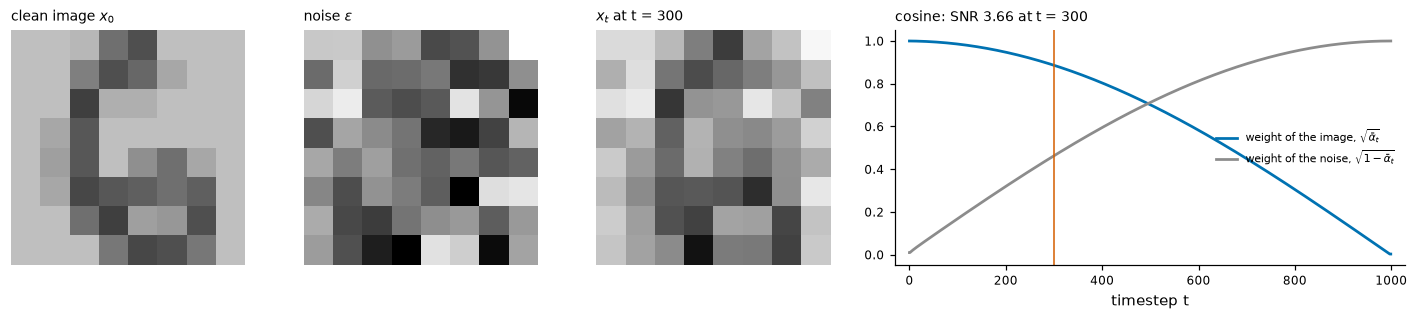

In [4]:
def forward_explorer(t=300, schedule="cosine", image=0):
    ab = D.alpha_bar(schedule)
    xt = ab[t].sqrt() * Xte[image] + (1 - ab[t]).sqrt() * noise[image]
    fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.8]))
    for ax, im, title in zip(axes, [Xte[image], noise[image], xt], ["clean image $x_0$", r"noise $\epsilon$", f"$x_t$ at t = {t}"]):
        ax.imshow(im.view(8, 8), cmap="gray_r", vmin=-2, vmax=2); ax.axis("off"); ax.set_title(title, fontsize=9)
    axes[3].plot(ab.sqrt(), color=viz.BLUE, label=r"weight of the image, $\sqrt{\bar\alpha_t}$"); axes[3].plot((1 - ab).sqrt(), color=viz.GREY, label=r"weight of the noise, $\sqrt{1-\bar\alpha_t}$")
    axes[3].axvline(t, color=viz.VERMILION, lw=1); axes[3].set_xlabel("timestep t"); axes[3].legend(fontsize=7, loc="center right")
    axes[3].set_title(f"{schedule}: SNR {float(ab[t] / (1 - ab[t])):.3g} at t = {t}", fontsize=9)
    plt.show()
viz.explore(forward_explorer, t=(0, 999, 1, 300), schedule=["cosine", "linear", "sd-linear"], image=(0, 50, 1, 0))

## 2. Training a denoiser: the recipe of 2020

The network $\epsilon_\theta(x_t, t, c)$ receives a noisy image, the timestep and a class label $c$, and is trained
to predict the noise that was added ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)):

$$\mathcal{L} = \mathbb{E}_{x_0,\, t,\, \epsilon}\;\big\lVert \epsilon - \epsilon_\theta(x_t, t, c) \big\rVert^2 .$$

One training step is five lines: draw images, draw a timestep for each, draw noise, mix them with the formula of
section 1, regress. There is no second network and no contest. This is the loss that [Ho et al., 2020](https://arxiv.org/abs/2006.11239) called "simple",
and it is a reweighted form of the variational bound of [Sohl-Dickstein et al., 2015](https://arxiv.org/abs/1503.03585). The same quantity is, up to scale, an
estimate of the gradient of the log-density of the noisy data, the *score* of [Song & Ermon, 2019](https://arxiv.org/abs/1907.05600); [Song et al., 2020](https://arxiv.org/abs/2011.13456) showed
that the two lines of work are one model.

**Sampling** runs the process backwards. Start from $x_T \sim \mathcal{N}(0, I)$. At each step use the predicted
noise to estimate the clean image,

$$\hat x_0 = \frac{x_t - \sqrt{1 - \bar\alpha_t}\,\epsilon_\theta}{\sqrt{\bar\alpha_t}},$$

and move to the next, less noisy timestep by re-noising $\hat x_0$ to that level. The sampler of [Ho et al., 2020](https://arxiv.org/abs/2006.11239) takes all
1,000 steps and adds fresh noise at each.

Our network is a small residual MLP (about 300,000 parameters). The timestep enters through the sinusoidal
features of notebook 03, and the label through an embedding. We first train the original recipe: linear schedule,
noise prediction, every timestep weighted equally.

299,328 parameters, 3,000 steps, 14 s
sampling 359 images with 1,000 steps: 2.4 s


,fd,precision,coverage,nn_ratio,judge_acc,nfe
model,,,,,,
real data,5.4,0.96,0.96,1.02,0.98,0
"DDPM recipe (linear schedule, predicts noise), 1,000 steps",30.3,0.90,0.83,0.98,0.99,1000


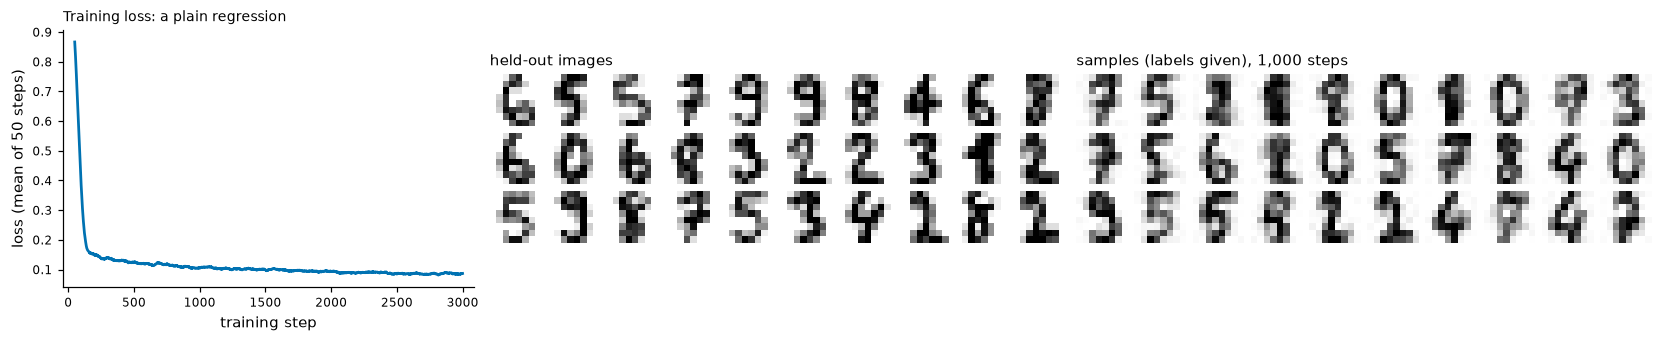

saved figures/nb07_sampling.gif  (29 frames drawn, 597 kB)


'figures/nb07_sampling.gif'

In [5]:
ddpm = run("linear, noise", D.Diffusion("linear", "eps"))
print(f"{ddpm['params']:,} parameters, {len(ddpm['losses']):,} steps, {ddpm['seconds']:.0f} s")
t0 = time.time()
x_ddpm = sample("linear, noise", steps=1000, eta=1.0)                       # the sampler of 2020: 1,000 steps with fresh noise at each
print(f"sampling {N} images with 1,000 steps: {time.time() - t0:.1f} s")
score(x_ddpm, "DDPM recipe (linear schedule, predicts noise), 1,000 steps", nfe=1000, labels=LABELS)
display(table(["real data", "DDPM recipe (linear schedule, predicts noise), 1,000 steps"]))

_, frames = ddpm["diff"].sample(ddpm["model"], LABELS[:16], steps=1000, eta=1.0, record=True)      # sixteen images, every step recorded
fig, axes = plt.subplots(1, 3, figsize=(15, 3), gridspec_kw=dict(width_ratios=[1, 1.4, 1.4]))
smooth = pd.Series(ddpm["losses"]).rolling(50).mean()
axes[0].plot(smooth, color=viz.BLUE); axes[0].set_xlabel("training step"); axes[0].set_ylabel("loss (mean of 50 steps)"); axes[0].set_title("Training loss: a plain regression", fontsize=9)
images.show_grid(Xte[:30], nrow=10, ax=axes[1], title="held-out images")
images.show_grid(x_ddpm[:30], nrow=10, ax=axes[2], title="samples (labels given), 1,000 steps")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 2.1))
keep = list(range(0, 1000, 50)) + [960, 980, 990, 999]
def frame(k):
    t, xt, x0 = frames[k]
    for ax in axes:
        ax.clear()
    images.show_grid(xt, nrow=8, ax=axes[0]); axes[0].set_title(f"the sample so far, $x_t$ at t = {t}", fontsize=10)
    images.show_grid(x0, nrow=8, ax=axes[1]); axes[1].set_title("the network's current estimate of the clean image", fontsize=10)
viz.save_gif(fig, frame, keep + [999] * 5, "nb07_sampling.gif", fps=4)

![Sampling sixteen digits: the noisy sample on the left, the network's estimate of the clean image on the right](figures/nb07_sampling.gif)

**What happened.** Training is an ordinary regression. The loss falls smoothly, and nothing has to be balanced
against anything else. Sampling 359 images with 1,000 steps takes a few seconds only because the network is tiny.

In the animation the sample itself (left) looks like noise for most of the trajectory. The network's estimate of the
clean image (right) is a rough blob at $t = 799$ and a recognisable digit by $t = 599$. The decisions about what the
image will be are made early, at high noise, and the later steps fill in detail.

The samples score FD 30.3, precision 0.90 and coverage 0.83, and the judge reads 0.99 of them as the requested
digit. Compare with the table of notebook 06 at the top:

* precision and coverage are above every model of notebook 06 (the best there was the pixel model, 0.82 and 0.72);
* FD is *worse* than the WGAN-GP (13.8) and the pixel model (14.6);
* and this model is given the label of each image, which those models were not. Section 11 makes the comparison
  fair.

So the recipe of 2020, at our budget, is not yet a clear winner. The rest of the notebook changes one choice at a
time.

### Try it: what the network sees, and what it guesses

Static preview at the default settings {'t': 600, 'image': 0}. Run the notebook to get the controls.


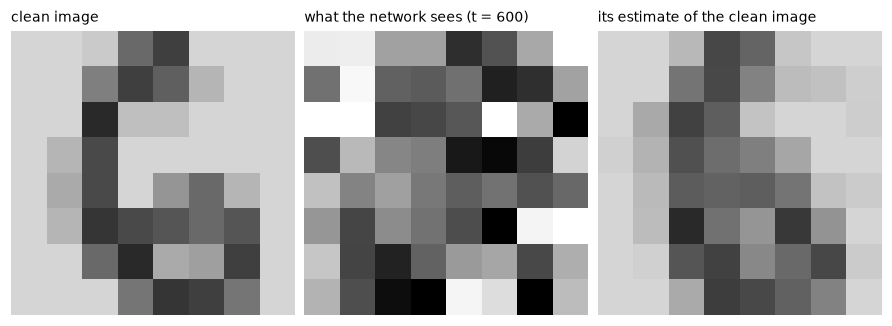

In [6]:
def denoise_explorer(t=600, image=0):
    diff, model = ddpm["diff"], ddpm["model"]
    tt = torch.tensor([t])
    xt = diff.q_sample(Xte[image:image + 1], tt, noise[image:image + 1])
    with torch.no_grad():
        x0_hat, _ = diff.to_x0_eps(model(xt, tt, yte[image:image + 1]), xt, tt)
    fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
    for ax, im, title in zip(axes, [Xte[image], xt[0], x0_hat[0].clamp(-1, 1)], ["clean image", f"what the network sees (t = {t})", "its estimate of the clean image"]):
        ax.imshow(im.view(8, 8), cmap="gray_r", vmin=-1.5, vmax=1.5); ax.axis("off"); ax.set_title(title, fontsize=9)
    plt.show()
viz.explore(denoise_explorer, t=(0, 999, 1, 600), image=(0, 50, 1, 0))

## 3. Design choice: the sampler and the number of steps

A thousand network evaluations per image is slow, and it was the main objection to diffusion in 2020.
[Song et al., 2020](https://arxiv.org/abs/2010.02502) noticed that the trained network does not depend on the sampler. The same network can be used with
a **deterministic** update (DDIM) that needs no fresh noise, and that can skip most of the timesteps. With a
parameter $\eta$ the update moves between the two: $\eta = 0$ is deterministic and $\eta = 1$ adds as much noise as
the sampler of 2020.

We take the model just trained and change only the sampler.

fd                                             coverage                                
sampler deterministic (DDIM) fresh noise at each step (DDPM) deterministic (DDIM) fresh noise at each step (DDPM)
steps                                                                                                            
5                      64.99                           76.12                 0.63                            0.50
10                     43.37                           47.00                 0.78                            0.75
20                     35.84                           38.90                 0.81                            0.79
50                     32.48                           36.13                 0.81                            0.78
100                    32.08                           32.47                 0.80                            0.84
250                    31.94                           31.71                 0.80                            0.81
1000                   31.87                           30.31                 0.80                            0.83

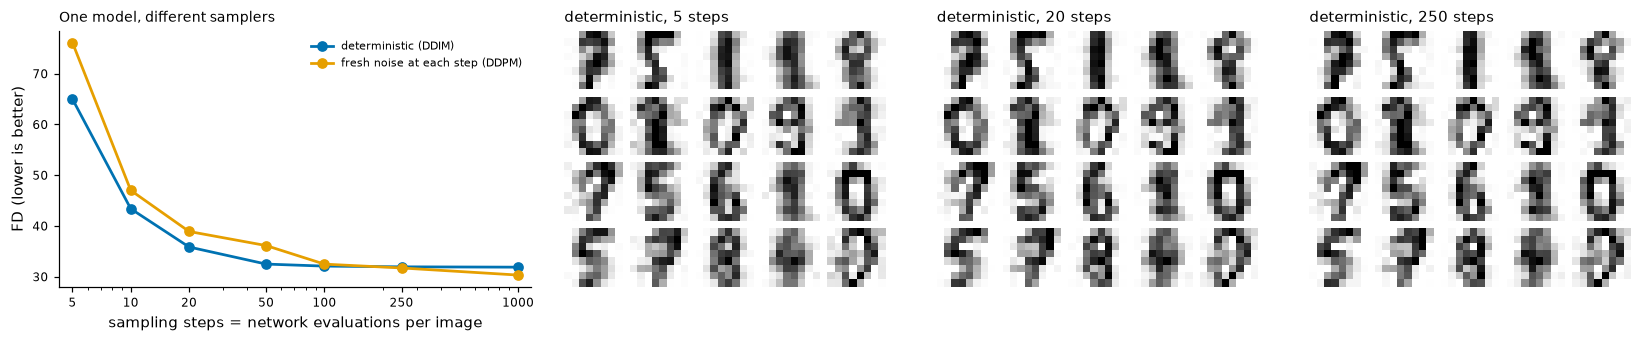

In [7]:
rows = []
for steps in (5, 10, 20, 50, 100, 250, 1000):
    for eta, kind in ((0.0, "deterministic (DDIM)"), (1.0, "fresh noise at each step (DDPM)")):
        r = report("linear, noise", steps=steps, eta=eta, keep=False)
        rows.append(dict(steps=steps, sampler=kind, fd=r["fd"], precision=r["precision"], coverage=r["coverage"], nn_ratio=r["nn_ratio"]))
steps_table = pd.DataFrame(rows)
display(steps_table.pivot(index="steps", columns="sampler", values=["fd", "coverage"]).round(2))
fig, axes = plt.subplots(1, 4, figsize=(15, 3), gridspec_kw=dict(width_ratios=[1.3, 1, 1, 1]))
for kind, col in (("deterministic (DDIM)", viz.BLUE), ("fresh noise at each step (DDPM)", viz.ORANGE)):
    d = steps_table[steps_table.sampler == kind]; axes[0].plot(d.steps, d.fd, "o-", color=col, label=kind)
axes[0].set_xscale("log"); axes[0].set_xticks([5, 10, 20, 50, 100, 250, 1000]); axes[0].set_xticklabels([5, 10, 20, 50, 100, 250, 1000]); axes[0].tick_params(axis="x", which="minor", labelbottom=False)
axes[0].set_xlabel("sampling steps = network evaluations per image"); axes[0].set_ylabel("FD (lower is better)"); axes[0].set_title("One model, different samplers", fontsize=9); axes[0].legend(fontsize=7, loc="upper right")
for ax, steps in zip(axes[1:], (5, 20, 250)):
    images.show_grid(sample("linear, noise", steps=steps)[:20], nrow=5, ax=ax, title=f"deterministic, {steps} steps")
plt.show()

**What happened.** One trained network, fourteen ways of sampling it.

* **Fifty deterministic steps are enough**: FD 32.5, against 30.3 for the original sampler with 1,000 steps. That
  is 20 times fewer network evaluations for a difference of about 2 in FD. Beyond 50 steps the deterministic
  sampler gains almost nothing (32.1 at 100 steps, 31.9 at 1,000).
* **Below 20 steps quality falls quickly**: 35.8 at 20 steps, 43.4 at 10, 65.0 at 5.
* **With few steps, determinism is better** (at 5 steps, 65.0 against 76.1). With 1,000 steps the sampler that adds
  noise is slightly ahead (30.3 against 31.9).

From here on every model is sampled with 50 deterministic steps. This choice needs no retraining, which is why
samplers improved faster than anything else between 2020 and 2022.

## 4. Design choice: the noise schedule

[Nichol & Dhariwal, 2021](https://arxiv.org/abs/2102.09672) observed that the linear schedule destroys the image too early at low resolution: the last part of
the forward process is spent on images that are already noise, and those timesteps teach the network little. Their
cosine schedule spreads the destruction more evenly. Section 1 showed the difference on our digits. Now we train the
same network on the cosine schedule and compare. Each run is also measured every 500 steps, and the cosine run is
repeated with two more seeds so that we know how much two runs of the same recipe differ.

,fd,precision,coverage,nn_ratio,judge_acc,nfe,fd with 10 steps
model,,,,,,,
"linear, noise",32.5,0.90,0.81,0.98,0.93,50,43.4
"cosine, noise",25.2,0.87,0.83,0.96,0.89,50,26.2


cosine schedule, two more seeds: FD 25.6 and 25.1


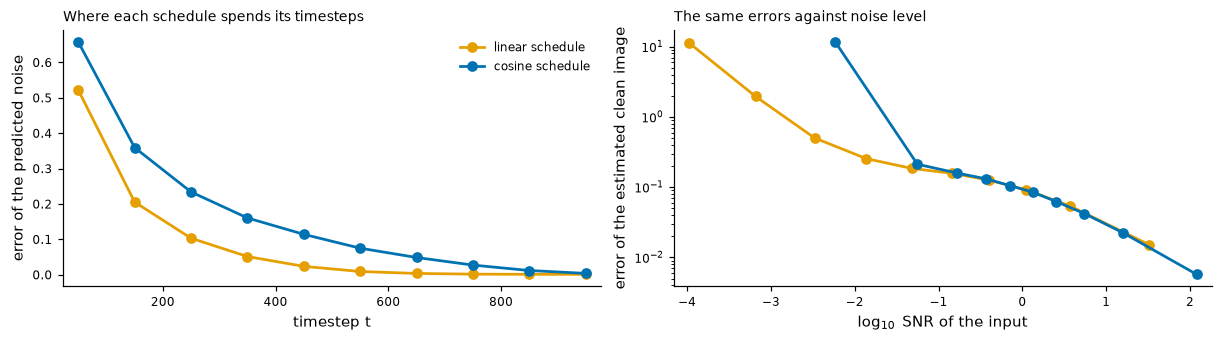

In [8]:
run("cosine, noise", D.Diffusion("cosine", "eps"), track=True)
for seed in (1, 2):
    run(f"cosine, noise, seed {seed}", D.Diffusion("cosine", "eps"), seed=seed)
report("linear, noise"); report("cosine, noise")
spread = [report(f"cosine, noise, seed {s}", keep=False)["fd"] for s in (1, 2)]
few = {n: report(n, steps=10, keep=False)["fd"] for n in ("linear, noise", "cosine, noise")}
t_ = table(["linear, noise", "cosine, noise"]); t_["fd with 10 steps"] = [round(few[n], 1) for n in t_.index]
display(t_)
print(f"cosine schedule, two more seeds: FD {spread[0]:.1f} and {spread[1]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for name, col in (("linear, noise", viz.ORANGE), ("cosine, noise", viz.BLUE)):
    r = RUNS[name]; centres, ex, ee = r["diff"].error_by_time(r["model"], Xte, yte)
    axes[0].plot(centres, ee, "o-", color=col, label=name.split(",")[0] + " schedule")
    axes[1].plot(torch.log10(r["diff"].snr[centres.astype(int)]), ex, "o-", color=col, label=name.split(",")[0] + " schedule")
axes[0].set_xlabel("timestep t"); axes[0].set_ylabel("error of the predicted noise"); axes[0].set_title("Where each schedule spends its timesteps", fontsize=9); axes[0].legend(fontsize=8, loc="upper right")
axes[1].set_xlabel(r"$\log_{10}$ SNR of the input"); axes[1].set_ylabel("error of the estimated clean image"); axes[1].set_yscale("log"); axes[1].set_title("The same errors against noise level", fontsize=9)
plt.show()

**What happened.** The cosine schedule gives an FD of 25.2 against 32.5 for the linear schedule. Two more seeds of
the cosine run give 25.6 and 25.1, so two runs of one recipe differ by about half a point, and the difference
between the schedules is far outside that. With 10 sampling steps the gap is wider: 26.2 against 43.4. The other
columns do not all agree: precision (0.87 against 0.90) and the judge's accuracy (0.89 against 0.93) are a little
lower with the cosine schedule, and coverage a little higher (0.83 against 0.81).

The figure shows the mechanism that [Nichol & Dhariwal, 2021](https://arxiv.org/abs/2102.09672) described. In the left panel, the error of the predicted noise
under the linear schedule is close to zero over the second half of the timesteps. Those inputs are almost pure
noise, the answer is almost the input, and the network learns little from them. In the right panel the same errors
are plotted against the noise level, and the two curves lie on top of each other wherever they overlap. Both
networks learned the same denoiser. The schedule only decides how the 1,000 timesteps are spread over the noise
levels.

The last point of each curve is far above the rest: at the highest noise level the estimate of the clean image from
a noise prediction has an error above 10. That is the subject of the next section.

## 5. Design choice: what the network predicts

The network could output three different things, and each determines the others, because $x_t$ is known:

| Target | Definition | Clean image from the output |
|---|---|---|
| noise $\epsilon$ ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)) | $\epsilon$ | $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$ |
| clean image $x_0$ | $x_0$ | $\hat x_0$ directly |
| velocity $v$ ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)) | $\sqrt{\bar\alpha_t}\,\epsilon - \sqrt{1-\bar\alpha_t}\,x_0$ | $\hat x_0 = \sqrt{\bar\alpha_t}\,x_t - \sqrt{1-\bar\alpha_t}\,\hat v$ |

The three are the same model on paper. They differ in two ways that matter in practice.

**As a loss weight.** An error in one output is a scaled error in another. Writing every loss as an error on the
clean image,

$$\lVert \epsilon - \hat\epsilon \rVert^2 = \text{SNR}(t)\,\lVert x_0 - \hat x_0 \rVert^2, \qquad
\lVert v - \hat v \rVert^2 = \big(1 + \text{SNR}(t)\big)\,\lVert x_0 - \hat x_0 \rVert^2 .$$

So plain squared error on the noise gives almost no weight to the noisiest timesteps, plain squared error on the
clean image weights all timesteps equally, and $v$ is in between.

**As a task for the network.** At high noise the input is almost pure noise. Predicting the noise is then close to
copying the input, and the estimate of the clean image divides a small difference by $\sqrt{\bar\alpha_t} \approx
0$: any error is amplified. At low noise the roles reverse: predicting the clean image is close to copying the input.
$v$ was introduced so that neither end is degenerate.

[Ho et al., 2020](https://arxiv.org/abs/2006.11239) tried both of the first two on real images with a U-Net and found that predicting the noise gave better
samples; that became the default. We train all three on the cosine schedule.

,fd,precision,coverage,nn_ratio,judge_acc,nfe,fd with 10 steps
model,,,,,,,
"cosine, noise",25.2,0.87,0.83,0.96,0.89,50,26.2
"cosine, clean image",8.5,0.97,0.95,0.91,0.97,50,9.7
"cosine, v",30.6,0.92,0.81,0.96,0.98,50,34.4


FD of two more seeds: noise [25.6, 25.1]  clean image [9.4, 9.1]


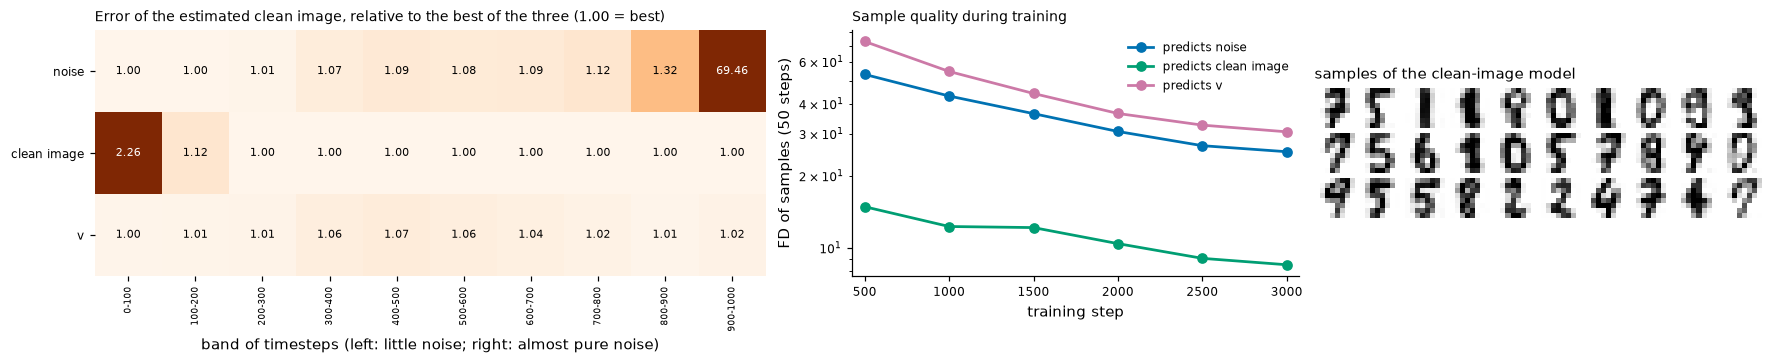

error of the estimated clean image in the noisiest band: {'noise': 11.68, 'clean image': 0.168, 'v': 0.172}


In [9]:
run("cosine, clean image", D.Diffusion("cosine", "x0"), track=True)
run("cosine, v", D.Diffusion("cosine", "v"), track=True)
for seed in (1, 2):
    run(f"cosine, clean image, seed {seed}", D.Diffusion("cosine", "x0"), seed=seed)
targets = ["cosine, noise", "cosine, clean image", "cosine, v"]
for n in targets[1:]:
    report(n)
t_ = table(targets); t_["fd with 10 steps"] = [round(report(n, steps=10, keep=False)["fd"], 1) for n in targets]
display(t_)
print("FD of two more seeds: noise", [round(s, 1) for s in spread], " clean image", [round(report(f"cosine, clean image, seed {s}", keep=False)["fd"], 1) for s in (1, 2)])

errs = {n: RUNS[n]["diff"].error_by_time(RUNS[n]["model"], Xte, yte) for n in targets}
centres = errs[targets[0]][0]
E = np.stack([errs[n][1] for n in targets])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
viz.heat(axes[0], E / E.min(0), xlabels=[f"{int(c - 50)}-{int(c + 50)}" for c in centres], ylabels=[n.split(", ")[1] for n in targets], annotate=True, fmt="{:.2f}", cmap="Oranges", vmin=1, vmax=2)
axes[0].tick_params(axis="x", labelsize=6); axes[0].set_xlabel("band of timesteps (left: little noise; right: almost pure noise)")
axes[0].set_title("Error of the estimated clean image, relative to the best of the three (1.00 = best)", fontsize=9)
for n, col in zip(targets, (viz.BLUE, viz.GREEN, viz.PINK)):
    axes[1].plot(RUNS[n]["track"]["EMA weights"], "o-", color=col, label="predicts " + n.split(", ")[1])
axes[1].set_yscale("log"); axes[1].set_xlabel("training step"); axes[1].set_ylabel("FD of samples (50 steps)"); axes[1].set_title("Sample quality during training", fontsize=9); axes[1].legend(fontsize=8, loc="upper right")
images.show_grid(sample("cosine, clean image")[:30], nrow=10, ax=axes[2], title="samples of the clean-image model")
plt.show()
print("error of the estimated clean image in the noisiest band:", {n.split(", ")[1]: round(float(errs[n][1][-1]), 3) for n in targets})

**What happened.** Not what the default of 2020 would lead one to expect.

* **Predicting the clean image is far better here**: FD 8.5, against 25.2 for the noise and 30.6 for $v$, with
  precision 0.97 and coverage 0.95. Three seeds give 8.5, 9.4 and 9.1 against 25.2, 25.6 and 25.1, so the ranges do
  not come near each other. It is also ahead throughout training (middle panel) and loses little with 10 sampling
  steps (9.7).
* **$v$, designed as the balanced target, has the worst FD** (30.6), although the judge reads 0.98 of its samples
  as the requested digit.
* **The heat map does not explain the ranking.** It behaves as the algebra says: the noise-predicting network
  cannot recover the image in the noisiest band (error 11.68 against 0.168, 69 times the best), and the
  clean-image network is the worst at low noise (2.26 times the best error in the first band). The $v$ network is
  within 7% of the best in every band. By this table $v$ should give the best samples. It gives the worst. The
  denoising error on real images with noise added does not predict the quality of samples here.

### Where does the difference come from? Swapping the networks during sampling

The three networks were trained on the same schedule, so they can be exchanged in the middle of a sampling run: one
network for the noisy part of the trajectory (timesteps at or above a switch point) and another for the rest. If the
advantage of the clean-image network lies in the noisy steps, it should survive when only those steps use it.

other network predicts                                 noise                                                                            v                                       
                       clean-image network for the last part clean-image network for the first part clean-image network for the last part clean-image network for the first part
switch at timestep                                                                                                                                                              
0                                                       25.2                                    8.5                                  30.6                                    8.5
100                                                     12.1                                   15.3                                  11.3                                   16.9
200                                                     12.2                                   16.9                                  11.0                                   19.4
400                                                     10.8                                   20.5                                   9.8                                   23.4
600                                                      9.7                                   23.9                                   8.9                                   26.8
800                                                      9.0                                   25.9                                   8.5                                   29.5
1000                                                     8.5                                   25.2                                   8.5                                   30.6

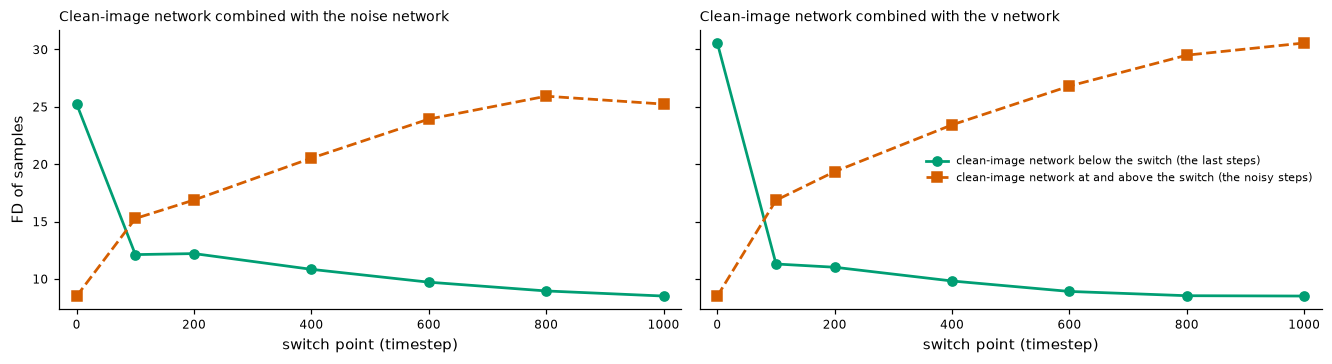

,fd,precision,coverage,nn_ratio,median distance to nearest training image
v network only,30.57,0.92,0.81,0.96,2.13
"v network down to t = 200, then clean-image network",11.02,0.96,0.94,0.93,1.91
"clean-image network down to t = 200, then v network",19.36,0.96,0.90,0.93,1.96
clean-image network only,8.51,0.97,0.95,0.91,1.79


In [10]:
x0_sampler = D.Diffusion("cosine", "x0")
pair = lambda name: (RUNS[name]["diff"], RUNS[name]["model"])
def hybrid(high, low, switch):
    # `high` for timesteps >= switch (the noisy part), `low` below (the last part); labels given, 50 steps
    return x0_sampler.sample(D.Hybrid(pair(high), pair(low), switch), LABELS, steps=50)
SWITCH = [0, 100, 200, 400, 600, 800, 1000]
swap = {}
for other in ("cosine, noise", "cosine, v"):
    swap[(other, "last")] = [score(hybrid(other, "cosine, clean image", s), "hybrid", 50, keep=False)["fd"] for s in SWITCH]      # clean-image network below the switch
    swap[(other, "first")] = [score(hybrid("cosine, clean image", other, s), "hybrid", 50, keep=False)["fd"] for s in SWITCH]     # clean-image network at and above it
sw = pd.DataFrame({(o.split(", ")[1], f"clean-image network for the {k} part") : v for (o, k), v in swap.items()}, index=pd.Index(SWITCH, name="switch at timestep")).round(1)
sw.columns.names = ["other network predicts", ""]
display(sw)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, other in zip(axes, ("cosine, noise", "cosine, v")):
    ax.plot(SWITCH, swap[(other, "last")], "o-", color=viz.GREEN, label="clean-image network below the switch (the last steps)")
    ax.plot(SWITCH, swap[(other, "first")], "s--", color=viz.VERMILION, label="clean-image network at and above the switch (the noisy steps)")
    ax.set_xlabel("switch point (timestep)"); ax.set_title(f"Clean-image network combined with the {other.split(', ')[1]} network", fontsize=9)
axes[0].set_ylabel("FD of samples"); axes[1].legend(fontsize=7, loc="center right")
plt.show()
mix = {"v network only": sample("cosine, v"), "v network down to t = 200, then clean-image network": hybrid("cosine, v", "cosine, clean image", 200),
       "clean-image network down to t = 200, then v network": hybrid("cosine, clean image", "cosine, v", 200), "clean-image network only": sample("cosine, clean image")}
display(pd.DataFrame({k: {**{c: v for c, v in score(x, k, 50, labels=LABELS, keep=False).items() if c in ("fd", "precision", "coverage", "nn_ratio")},
                          "median distance to nearest training image": float(torch.cdist(x, Xtr).min(1).values.median())} for k, x in mix.items()}).T.round(2))

**What happened.** The advantage of the clean-image network lies mostly in the **last** steps, which is exactly
where its denoising error was worst.

* Use the $v$ network for the noisy steps and the clean-image network only below $t = 100$, the last five of the
  50 sampling steps. FD falls from 30.6 to 11.3. With the noise network in place of the $v$ network: from 25.2 to
  12.1.
* The reverse, the clean-image network for everything except the last 100 timesteps, gives 16.9 and 15.3. The
  noisy steps matter as well, but less.
* The second table shows a side effect. Finishing with the clean-image network moves the samples closer to the
  training images: a median distance of 1.91 to the nearest one, against 2.13 for the $v$ network alone and 1.79
  for the clean-image network alone.

**An interpretation**, which we have not tested further. The heat map measured each network on real images with
Gaussian noise added. During sampling, the inputs at low noise are something else: the sampler's own unfinished
images, whose errors are not Gaussian noise. A network that outputs the noise makes a small correction to its input
and keeps the rest. For a real image at low noise that is the right thing to do, and it leaves the sampler's own
errors in place. A network that outputs the clean image redraws the whole image at every step, towards what it has
learned a digit looks like. On noised real images the redrawing costs accuracy. On unfinished samples it works as a
clean-up.

**Why did [Ho et al., 2020](https://arxiv.org/abs/2006.11239) find the opposite?** We do not know. Their network was a U-Net on tens of thousands of real
images; ours is a small MLP on 1,438 digits with 64 pixels. [Li & He, 2025](https://arxiv.org/abs/2511.13720) recently argued for returning to clean-image
prediction for a different reason, that images lie near a low-dimensional surface and noise does not, so a network
of limited capacity can output the first and not the second. Our result is consistent with that view and does not
prove it. Treat the ranking as a property of this setting, and the method (swap networks during sampling) as the
thing to take away.

### A check before believing a low FD: is the model copying its training set?

We have 1,438 training images, and section 1 of notebook 06 showed that copies of training images get a perfect FD.
A denoiser can lower its training loss by learning the training images themselves ([Carlini et al., 2023](https://arxiv.org/abs/2301.13188) extracted
training images from large diffusion models; [Kadkhodaie et al., 2023](https://arxiv.org/abs/2310.02557) showed that whether a denoiser memorises or
generalises depends on how much data it has). Three measurements tell us where our models stand.

* **nn_ratio** from the scorecard: below 1 means samples lie closer to training images than to held-out ones.
* The **denoising error on training images divided by the error on held-out images**, at the lowest noise level,
  where remembering a particular image helps most. A ratio of 1 means no memorisation.
* The **distance from a sample to the nearest training image**, compared with the same distance for held-out
  images.

In [11]:
def memorisation(name):
    r = RUNS[name]
    e_tr = r["diff"].error_by_time(r["model"], Xtr[:N], ytr[:N])[1]; e_te = r["diff"].error_by_time(r["model"], Xte, yte)[1]
    d = torch.cdist(sample(name), Xtr).min(1).values
    return {"nn_ratio": ROWS[name]["nn_ratio"] if name in ROWS else report(name, keep=False)["nn_ratio"],
            "training / held-out error, least noise": e_tr[0] / e_te[0], "training / held-out error, most noise": e_tr[-1] / e_te[-1],
            "median distance to nearest training image": float(d.median()), "samples within 0.5 of a training image": int((d < 0.5).sum())}
d_real = torch.cdist(Xte, Xtr).min(1).values
print(f"held-out images: median distance to the nearest training image {float(d_real.median()):.2f}; {int((d_real < 0.5).sum())} of {N} within 0.5")
display(pd.DataFrame({n: memorisation(n) for n in targets}).T.round(2))

held-out images: median distance to the nearest training image 2.07; 0 of 359 within 0.5


,nn_ratio,"training / held-out error, least noise","training / held-out error, most noise",median distance to nearest training image,samples within 0.5 of a training image
"cosine, noise",0.96,0.84,1.01,2.29,0.0
"cosine, clean image",0.91,0.77,0.98,1.79,0.0
"cosine, v",0.96,0.86,0.98,2.13,0.0


**Reading the table.**

* **No model copies.** No sample lies within 0.5 of a training image. Typical distances to the nearest training
  image are around 2, and the same is true of held-out images (2.07).
* **All three have begun to learn the training images themselves.** At the lowest noise level the denoising error
  on training images is lower than on held-out images (ratios 0.84, 0.77 and 0.86). At the highest noise level
  there is no difference (0.98 to 1.01). This is where memorisation would start: at low noise a particular training
  image can still be recognised in the input.
* **The clean-image network has gone furthest.** Its ratio is 0.77 and its nn_ratio 0.91, and its samples are
  closer to the training set (1.79) than held-out images are (2.07). The samples of the other two are slightly
  further away than held-out images (2.29 and 2.13).

So the clean-image network's samples are better by every score, and they also lean a little towards the training
set. An FD against held-out images cannot separate the two, since exact copies would score about 5. We keep both
columns in view, and section 11 shows what longer training does to them.

### An interaction: zero terminal SNR

[Lin et al., 2023](https://arxiv.org/abs/2305.08891) pointed out a flaw in the schedules that were in use. At the last timestep a little signal is left. For
the scaled-linear schedule of Stable Diffusion the terminal SNR is 0.0047, not 0. Training therefore never shows the
network pure noise, but sampling starts from pure noise. The leaked signal is mostly the lowest frequency of the
image, its mean brightness, and the visible symptom was that the model could not produce very dark or very bright
images. Their fix is to rescale the schedule so that the last step is exactly pure noise.

This interacts with the target. At SNR 0 the input *is* the noise, so "predict the noise" is answered by copying the
input and says nothing about the image. A schedule with zero terminal SNR needs a network that predicts $v$ or the
clean image. So the three runs below predict $v$:

* the scaled-linear schedule as used in Stable Diffusion (terminal SNR 0.0047);
* the same schedule rescaled to zero terminal SNR;
* a cosine schedule that we stop early on purpose, with a terminal SNR of 0.52, to show the mechanism at a size
  that cannot be missed.

,terminal SNR,fd,precision,coverage,mean brightness of a sample,spread of mean brightness
scaled linear,0.00468,30.5,0.91,0.84,-0.387,0.055
"scaled linear, zero terminal SNR",0.00000,29.2,0.94,0.84,-0.388,0.055
"cosine, stopped early",0.51701,111.9,0.52,0.34,-0.373,0.071
cosine (section 5),0.00001,30.6,0.92,0.81,-0.388,0.056


held-out images: mean brightness -0.392, spread 0.065


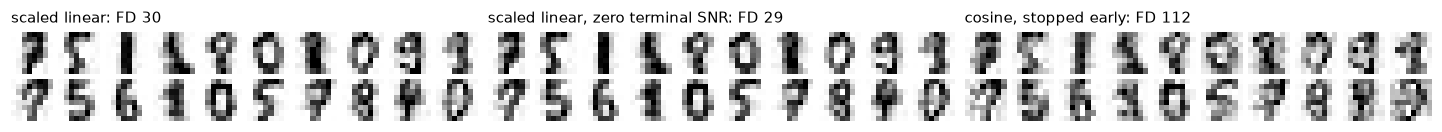

In [12]:
zt = {"scaled linear": "sd-linear", "scaled linear, zero terminal SNR": "sd-linear-zt", "cosine, stopped early": "cosine-short"}
rows = {}
for label, sched in zt.items():
    run(f"{label}, v", D.Diffusion(sched, "v"))
    r = report(f"{label}, v"); x = sample(f"{label}, v")
    rows[label] = {"terminal SNR": float(RUNS[f"{label}, v"]["diff"].snr[-1]), "fd": r["fd"], "precision": r["precision"], "coverage": r["coverage"],
                   "mean brightness of a sample": float(x.mean(1).mean()), "spread of mean brightness": float(x.mean(1).std())}
rows["cosine (section 5)"] = {"terminal SNR": float(RUNS["cosine, v"]["diff"].snr[-1]), **{k: ROWS["cosine, v"][k] for k in ("fd", "precision", "coverage")},
                              "mean brightness of a sample": float(sample("cosine, v").mean(1).mean()), "spread of mean brightness": float(sample("cosine, v").mean(1).std())}
display(pd.DataFrame(rows).T.round({"terminal SNR": 5, "fd": 1, "precision": 2, "coverage": 2, "mean brightness of a sample": 3, "spread of mean brightness": 3}))
print(f"held-out images: mean brightness {float(Xte.mean(1).mean()):.3f}, spread {float(Xte.mean(1).std()):.3f}")
fig, axes = plt.subplots(1, 3, figsize=(13, 2.2))
for ax, label in zip(axes, zt):
    images.show_grid(sample(f"{label}, v")[:20], nrow=10, ax=ax, title=f"{label}: FD {rows[label]['fd']:.0f}")
plt.show()

**What happened.**

* **The real schedules: no clear effect.** Rescaling the scaled-linear schedule to zero terminal SNR changes FD
  from 30.5 to 29.2 and precision from 0.91 to 0.94, and leaves coverage at 0.84. The mean brightness of the
  samples and its spread are the same in both (−0.39 and 0.055; the data have −0.39 and 0.065). The brightness
  symptom of [Lin et al., 2023](https://arxiv.org/abs/2305.08891) does not appear on 8×8 digits.
* **The exaggerated schedule: a large effect.** With a terminal SNR of 0.52, FD is 111.9, precision 0.52 and
  coverage 0.34. The network was never trained on what sampling starts from, and the samples show it.

Why does the real schedule not matter here? A calculation, not a measurement. With a terminal SNR of 0.0047 the
last training input is $0.068\,x_0 + 0.998\,\epsilon$. The mean brightness of a digit is about −0.39, so the leaked
mean is about −0.027. The mean of 64 independent noise pixels has a standard deviation of $1/8 = 0.125$, so the
leak is hidden under the noise. For the 16,384 numbers of a Stable Diffusion latent the mean of the noise has a
standard deviation of $1/128 \approx 0.008$, well below the same leak. The flaw grows with resolution, which is why
it was found in large image models and cannot be seen in ours.

## 6. Design choice: the weight of each noise level

Section 5 showed that the target sets a loss weight as a side effect. The weight can also be chosen directly.
[Kingma et al., 2021](https://arxiv.org/abs/2107.00630) showed that the losses in use differ only in how they weight the noise levels, and [Hang et al., 2023](https://arxiv.org/abs/2303.09556)
proposed a simple rule, **min-SNR**: give the error on the clean image at timestep $t$ the weight

$$w(t) = \min\big(\text{SNR}(t),\, \gamma\big), \qquad \gamma = 5 .$$

Their argument is that the timesteps compete. Low-noise timesteps have large SNR and dominate a noise-prediction
loss, although denoising an almost clean image is easy. Capping the weight stops them from crowding out the rest.
The rule can be applied with any target by converting the weight (`Diffusion.weight`).

,plain squared error: fd,min-SNR: fd,plain: coverage,min-SNR: coverage,"plain: fd at step 1,500","min-SNR: fd at step 1,500"
the network predicts,,,,,,
noise,25.24,20.19,0.83,0.91,36.41,29.16
clean image,8.51,7.82,0.95,0.94,12.17,11.88
v,30.57,22.79,0.81,0.89,44.20,35.01


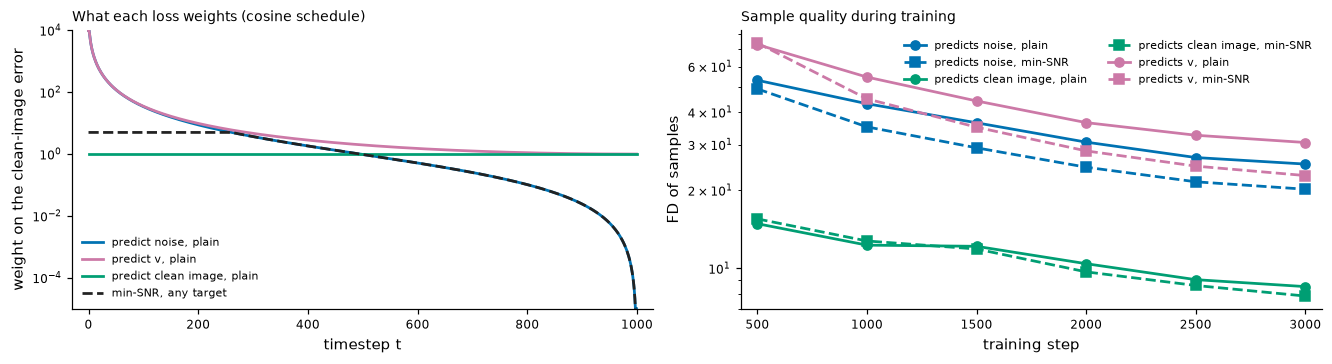

In [13]:
diff_c = D.Diffusion("cosine", "eps"); t_all = torch.arange(D.T)
weights = {"predict noise, plain": diff_c.snr, "predict v, plain": 1 + diff_c.snr, "predict clean image, plain": torch.ones(D.T), "min-SNR, any target": diff_c.snr.clamp(max=5.0)}
for pred, label in (("eps", "noise"), ("x0", "clean image"), ("v", "v")):
    run(f"cosine, {label}, min-SNR", D.Diffusion("cosine", pred, "min-snr"), track=True)
    report(f"cosine, {label}, min-SNR")
cmp = pd.DataFrame({label: {"plain squared error: fd": ROWS[f"cosine, {label}"]["fd"], "min-SNR: fd": ROWS[f"cosine, {label}, min-SNR"]["fd"],
                            "plain: coverage": ROWS[f"cosine, {label}"]["coverage"], "min-SNR: coverage": ROWS[f"cosine, {label}, min-SNR"]["coverage"],
                            "plain: fd at step 1,500": RUNS[f"cosine, {label}"]["track"]["EMA weights"].loc[1500], "min-SNR: fd at step 1,500": RUNS[f"cosine, {label}, min-SNR"]["track"]["EMA weights"].loc[1500]}
                    for label in ("noise", "clean image", "v")}).T
cmp.index.name = "the network predicts"
display(cmp.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for (name, w), col in zip(weights.items(), (viz.BLUE, viz.PINK, viz.GREEN, viz.BLACK)):
    axes[0].plot(t_all, w, color=col, label=name, ls="--" if name.startswith("min") else "-")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-5, 1e4); axes[0].set_xlabel("timestep t"); axes[0].set_ylabel("weight on the clean-image error")
axes[0].set_title("What each loss weights (cosine schedule)", fontsize=9); axes[0].legend(fontsize=7, loc="lower left")
for label, col in (("noise", viz.BLUE), ("clean image", viz.GREEN), ("v", viz.PINK)):
    axes[1].plot(RUNS[f"cosine, {label}"]["track"]["EMA weights"], "o-", color=col, label=f"predicts {label}, plain")
    axes[1].plot(RUNS[f"cosine, {label}, min-SNR"]["track"]["EMA weights"], "s--", color=col, label=f"predicts {label}, min-SNR")
axes[1].set_yscale("log"); axes[1].set_xlabel("training step"); axes[1].set_ylabel("FD of samples"); axes[1].set_title("Sample quality during training", fontsize=9); axes[1].legend(fontsize=7, ncol=2, loc="upper right")
plt.show()

**What happened.**

* **min-SNR helps the noise and $v$ networks**: FD 25.2 to 20.2 and 30.6 to 22.8, with coverage up from 0.83 to
  0.91 and from 0.81 to 0.89. They are also ahead half way through training (29.2 against 36.4, and 35.0 against
  44.2, at step 1,500), which is the faster convergence that [Hang et al., 2023](https://arxiv.org/abs/2303.09556) reported.
* **For the clean-image network it changes nothing measurable**: 8.5 to 7.8, inside the range of three seeds of
  that model (8.5 to 9.4).
* **The weight does not close the gap between targets.** With min-SNR all three networks are trained on the *same*
  weighting of the clean-image error, the dashed line of the left panel. Their FDs are 20.2, 7.8 and 22.8.

The last point is the lesson of sections 5 and 6 together. On paper the target is only a loss weight. In practice
the same weighted loss, asked of a network through a different output, trains a different model.

## 7. Design choice: telling the network the noise level

One network serves all noise levels, so it is told the level. The standard way is the sinusoidal feature vector of
the transformer's position encoding (notebook 03), passed through a small MLP and added inside every block. Is that
needed? We compare three inputs, for the noise-predicting and for the clean-image-predicting network:

* **sinusoidal** features of $t$ (the default);
* **one number**, $t / T$;
* **nothing**: the network has to infer the noise level from its input. [Sun et al., 2025](https://arxiv.org/abs/2502.13129) reported that many denoising
  models degrade only a little without noise conditioning.

fd  precision  coverage  judge_acc
the network predicts it is told the noise level by                                       
noise                sinusoidal                     25.24       0.87      0.83       0.89
                     scalar                         18.15       0.87      0.87       0.91
                     none                           78.86       0.65      0.85       0.76
clean image          sinusoidal                      8.51       0.97      0.95       0.97
                     scalar                          8.67       0.96      0.93       0.98
                     none                            9.67       0.99      0.96       0.99

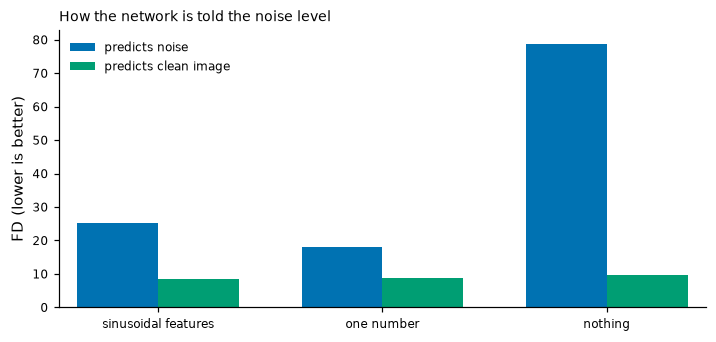

In [14]:
cond = {}
for label in ("noise", "clean image"):
    pred = "eps" if label == "noise" else "x0"
    cond[(label, "sinusoidal")] = ROWS[f"cosine, {label}"]
    for mode in ("scalar", "none"):
        run(f"cosine, {label}, time {mode}", D.Diffusion("cosine", pred), time=mode)
        cond[(label, mode)] = report(f"cosine, {label}, time {mode}")
tc = pd.DataFrame({k: {c: v[c] for c in ("fd", "precision", "coverage", "judge_acc")} for k, v in cond.items()}).T
tc.index.names = ["the network predicts", "it is told the noise level by"]
display(tc.round(2))
fig, ax = plt.subplots(figsize=(6.4, 3))
xs = np.arange(3)
for i, (label, col) in enumerate((("noise", viz.BLUE), ("clean image", viz.GREEN))):
    ax.bar(xs + (i - 0.5) * 0.36, [cond[(label, m)]["fd"] for m in ("sinusoidal", "scalar", "none")], width=0.36, color=col, label=f"predicts {label}")
ax.set_xticks(xs); ax.set_xticklabels(["sinusoidal features", "one number", "nothing"]); ax.set_ylabel("FD (lower is better)"); ax.set_title("How the network is told the noise level", fontsize=9); ax.legend(fontsize=8, loc="upper left")
plt.show()

**What happened.**

* **The noise-predicting network needs the noise level.** Without it FD rises from 25.2 to 78.9, and the judge
  recognises only 0.76 of its samples.
* **The clean-image network hardly needs it**: 8.5 with sinusoidal features, 8.7 with one number, 9.7 with nothing.
  The first two are inside the seed range of that model (8.5 to 9.4) and the third is just outside. This agrees
  with [Sun et al., 2025](https://arxiv.org/abs/2502.13129).
* **Sinusoidal features were not better than a single number.** For the noise network the single number was better
  (18.2 against 25.2, far outside the half point between seeds). We have one run of it and no explanation.

An interpretation of the first two results: "which clean image is this?" has the same answer at every noise level,
while "which part of this input is noise?" depends on how much noise there is.

## 8. Design choice: averaging the weights

Every diffusion paper samples from an **exponential moving average** (EMA) of the weights and not from the weights
at the last step ([Ho et al., 2020](https://arxiv.org/abs/2006.11239), following [Song & Ermon, 2019](https://arxiv.org/abs/1907.05600)). After each optimiser step, $\theta_{\text{EMA}} \leftarrow
d\,\theta_{\text{EMA}} + (1 - d)\,\theta$. The usual explanation is that the loss is noisy: every step sees random
timesteps and random noise, so the weights jitter around a good solution, and the average is closer to it than
any single iterate.

All runs so far tracked both sets of weights. We add one run with a **constant** learning rate, because our
default schedule decays the rate to zero, and a rate of zero is a kind of averaging too.

learning rate decays to zero              constant learning rate             
                      EMA weights last weights            EMA weights last weights
step                                                                              
500                          53.1         64.7                   53.3         64.4
1000                         43.1         47.4                   43.8         57.5
1500                         36.4         37.0                   38.1         40.5
2000                         30.7         31.9                   34.3         40.7
2500                         26.7         27.3                   31.8         47.7
3000                         25.2         24.8                   30.0         41.7

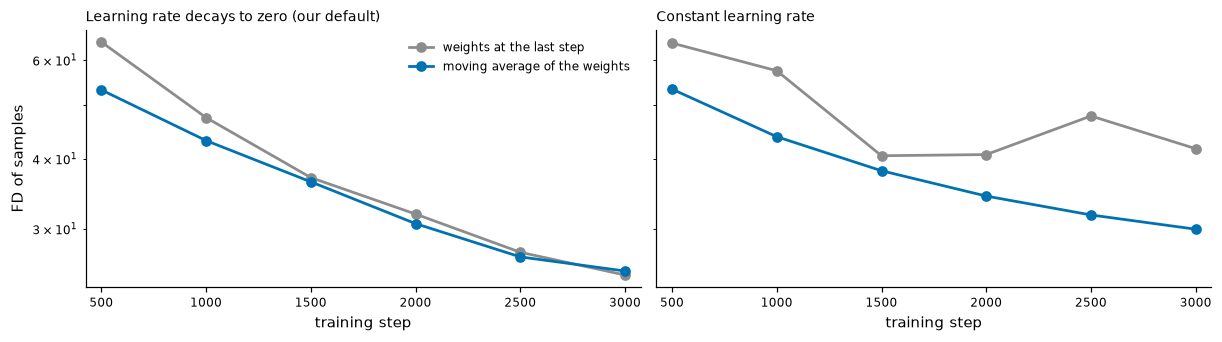

In [15]:
run("cosine, noise, constant rate", D.Diffusion("cosine", "eps"), track=True, lr_schedule="constant")
a, b = RUNS["cosine, noise"]["track"], RUNS["cosine, noise, constant rate"]["track"]
display(pd.concat({"learning rate decays to zero": a, "constant learning rate": b}, axis=1).round(1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, t, title in ((axes[0], a, "Learning rate decays to zero (our default)"), (axes[1], b, "Constant learning rate")):
    ax.plot(t["last weights"], "o-", color=viz.GREY, label="weights at the last step"); ax.plot(t["EMA weights"], "o-", color=viz.BLUE, label="moving average of the weights")
    ax.set_yscale("log"); ax.set_xlabel("training step"); ax.set_title(title, fontsize=9)
axes[0].set_ylabel("FD of samples"); axes[0].legend(fontsize=8, loc="upper right")
plt.show()

**What happened.**

* **With a constant learning rate the EMA matters a great deal.** The weights at the last step do not settle: FD
  40.5, 40.7, 47.7 and 41.7 at the last four measurements. The moving average improves steadily to 30.0.
* **With a learning rate that decays to zero, the EMA helps only early**: 53.1 against 64.7 at step 500, and 25.2
  against 24.8 at the end. A vanishing learning rate averages the noise away by itself.
* The decayed run is also better overall (25.2 against 30.0).

So the EMA is a remedy for noisy iterates at a learning rate that is still large. Large diffusion models are
commonly trained at a constant rate for a number of steps that is not fixed in advance, and that is the situation
in which the EMA is needed. All our other runs decay the rate, so their EMA changed little.

## 9. Design choice: label dropout and classifier-free guidance

Our denoiser has been conditional from the start: it receives the digit we want. Conditioning is what turns a
generator into a tool, and for diffusion models it comes with a control that no model of notebook 06 had.

**Classifier-free guidance** ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)). During training, replace the label by a special "no label" token with
some probability (10% so far). One network then gives two predictions for any input: a conditional one and an
unconditional one. At sampling time, extrapolate from the unconditional prediction past the conditional one:

$$\hat\epsilon = (1 + w)\,\epsilon_\theta(x_t, t, c) \;-\; w\,\epsilon_\theta(x_t, t, \varnothing).$$

$w = 0$ is ordinary conditional sampling. Larger $w$ pushes samples towards what distinguishes the class from the
average image. It costs two network evaluations per step. Text-to-image models owe much of their prompt fidelity to
it.

Two choices: the dropout rate in training, and the scale $w$ at sampling. We train with four dropout rates and
sample each at five scales.

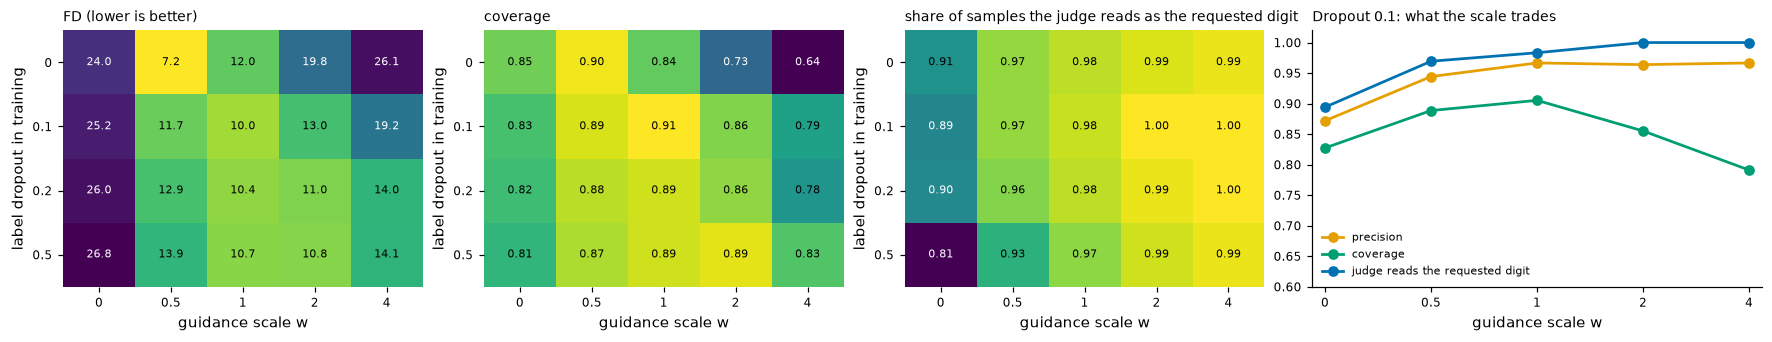

guidance scale             0.0    0.5    1.0    2.0    4.0
          label dropout                                   
fd        0.0            24.03   7.23  11.98  19.76  26.07
          0.1            25.24  11.71   9.97  12.97  19.19
          0.2            25.98  12.94  10.44  11.03  13.98
          0.5            26.76  13.94  10.72  10.79  14.07
coverage  0.0             0.85   0.90   0.84   0.73   0.64
          0.1             0.83   0.89   0.91   0.86   0.79
          0.2             0.82   0.88   0.89   0.86   0.78
          0.5             0.81   0.87   0.89   0.89   0.83
judge_acc 0.0             0.91   0.97   0.98   0.99   0.99
          0.1             0.89   0.97   0.98   1.00   1.00
          0.2             0.90   0.96   0.98   0.99   1.00
          0.5             0.81   0.93   0.97   0.99   0.99

FD in three seeds, at the best scale of each setting:


seed,0,1,2
"dropout 0, w = 0.5",7.2,16.2,7.9
"dropout 0.1, w = 1",10.0,10.4,10.3


guidance scale with the lowest FD, per dropout rate: {0.0: (0.5, 7.2), 0.1: (1.0, 10.0), 0.2: (1.0, 10.4), 0.5: (1.0, 10.7)}


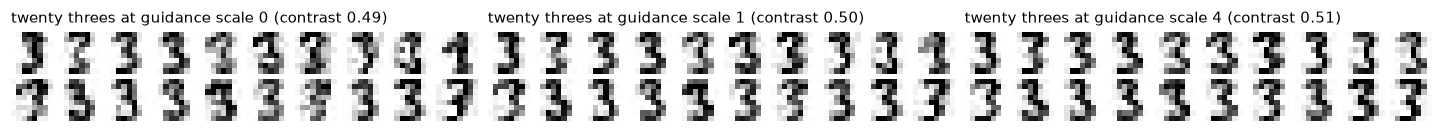

In [16]:
DROPS, SCALES = [0.0, 0.1, 0.2, 0.5], [0.0, 0.5, 1.0, 2.0, 4.0]
RUNS["cosine, noise, dropout 0.1"] = RUNS["cosine, noise"]
for p in (0.0, 0.2, 0.5):
    run(f"cosine, noise, dropout {p}", D.Diffusion("cosine", "eps"), p_uncond=p)
cfg = {(p, w): report(f"cosine, noise, dropout {p}", steps=50, w=w, keep=False) for p in DROPS for w in SCALES}
fig, axes = plt.subplots(1, 4, figsize=(16, 3), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.25]))
for ax, (key, title, cmap) in zip(axes, (("fd", "FD (lower is better)", "viridis_r"), ("coverage", "coverage", "viridis"), ("judge_acc", "share of samples the judge reads as the requested digit", "viridis"))):
    viz.heat(ax, np.array([[cfg[(p, w)][key] for w in SCALES] for p in DROPS]), xlabels=[f"{w:g}" for w in SCALES], ylabels=[f"{p:g}" for p in DROPS], annotate=True, fmt="{:.1f}" if key == "fd" else "{:.2f}", cmap=cmap)
    ax.set_xlabel("guidance scale w"); ax.set_ylabel("label dropout in training"); ax.set_title(title, fontsize=9)
ax = axes[3]
for key, col in (("precision", viz.ORANGE), ("coverage", viz.GREEN), ("judge_acc", viz.BLUE)):
    ax.plot(range(len(SCALES)), [cfg[(0.1, w)][key] for w in SCALES], "o-", color=col, label={"judge_acc": "judge reads the requested digit"}.get(key, key))
ax.set_xticks(range(len(SCALES))); ax.set_xticklabels([f"{w:g}" for w in SCALES]); ax.set_xlabel("guidance scale w"); ax.set_ylim(0.6, 1.02)
ax.set_title("Dropout 0.1: what the scale trades", fontsize=9); ax.legend(fontsize=7, loc="lower left")
plt.show()
grid = pd.concat({key: pd.DataFrame([[cfg[(p, w)][key] for w in SCALES] for p in DROPS], index=pd.Index(DROPS, name="label dropout"), columns=pd.Index(SCALES, name="guidance scale")) for key in ("fd", "coverage", "judge_acc")})
display(grid.round(2))
for seed in (1, 2):                                                                    # is guidance without dropout reliable? two more seeds
    run(f"cosine, noise, dropout 0.0, seed {seed}", D.Diffusion("cosine", "eps"), p_uncond=0.0, seed=seed)
seeds = pd.DataFrame({f"dropout {p:g}, w = {w:g}": [report(n, w=w, keep=False)["fd"] for n in names]
                      for p, w, names in ((0.0, 0.5, ["cosine, noise, dropout 0.0", "cosine, noise, dropout 0.0, seed 1", "cosine, noise, dropout 0.0, seed 2"]),
                                          (0.1, 1.0, ["cosine, noise", "cosine, noise, seed 1", "cosine, noise, seed 2"]))}, index=pd.Index([0, 1, 2], name="seed")).T
print("FD in three seeds, at the best scale of each setting:"); display(seeds.round(1))
best = {p: min(SCALES, key=lambda w: cfg[(p, w)]["fd"]) for p in DROPS}
print("guidance scale with the lowest FD, per dropout rate:", {p: (w, round(cfg[(p, w)]["fd"], 1)) for p, w in best.items()})
ROWS["cosine, noise, guidance 1"] = dict(cfg[(0.1, 1.0)], model="cosine, noise, guidance 1")

fig, axes = plt.subplots(1, 3, figsize=(13, 2.2))
threes = torch.full((20,), 3)
for ax, w in zip(axes, (0.0, 1.0, 4.0)):
    x3 = sample("cosine, noise", w=w, labels=threes)
    images.show_grid(x3, nrow=10, ax=ax, title=f"twenty threes at guidance scale {w:g} (contrast {G.contrast(x3):.2f})")
plt.show()

**What happened** (first table: FD, coverage and the judge's accuracy for every dropout rate and scale).

* **Guidance is the largest single improvement to the noise-predicting model.** With dropout 0.1, going from
  $w = 0$ to $w = 1$ takes FD from 25.2 to 10.0, the judge's accuracy from 0.89 to 0.98 and coverage from 0.83 to
  0.91. It doubles the cost of sampling.
* **Too much guidance costs diversity.** At $w = 4$ the judge's accuracy is 1.00, coverage has fallen to 0.79 and
  FD has risen to 19.2. The twenty threes show the same thing: at $w = 0$ a few are not threes, and at $w = 4$ all
  are threes and they resemble each other more.
* **The dropout rate matters little** between 0.1 and 0.5 once guidance is on (FD 10.0, 10.4 and 10.7 at $w = 1$).
  A high rate costs quality when guidance is off: at dropout 0.5 and $w = 0$ the judge's accuracy is 0.81.
* **A surprise in the first row.** With dropout 0 the "no label" token is never trained, so guidance against it
  should mean nothing. At $w = 0.5$ it gives the lowest FD of the whole grid (7.2), and then degrades quickly (19.8
  at $w = 2$). The second table shows that this is not dependable: over three seeds FD is 7.2, 16.2 and 7.9,
  against 10.0, 10.4 and 10.3 for dropout 0.1 at $w = 1$. What the untrained token does depends on the random
  vector it happens to hold. We have no fuller explanation. Label dropout is what makes guidance reliable.

### Try it: turn the guidance scale

Static preview at the default settings {'scale': 1.0, 'digit': 3, 'dropout': '0.1'}. Run the notebook to get the controls.


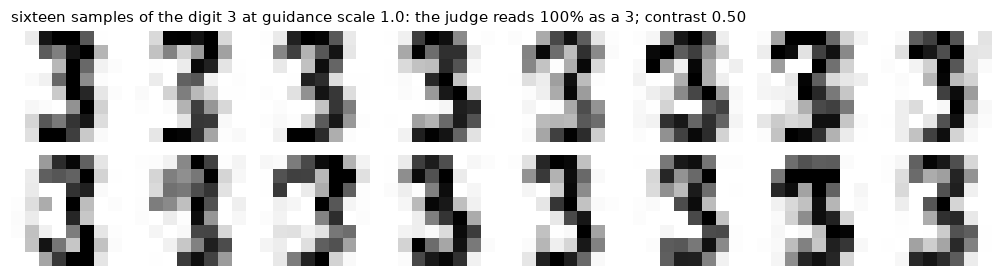

In [17]:
def guidance_explorer(scale=1.0, digit=3, dropout="0.1"):
    labels = torch.full((16,), int(digit))
    x = sample(f"cosine, noise, dropout {dropout}", w=scale, labels=labels)
    with torch.no_grad():
        right = float((judge(x).argmax(1) == labels).float().mean())
    fig, ax = plt.subplots(figsize=(9, 2.6))
    images.show_grid(x, nrow=8, ax=ax, title=f"sixteen samples of the digit {digit} at guidance scale {scale:.1f}: the judge reads {right:.0%} as a {digit}; contrast {G.contrast(x):.2f}")
    plt.show()
viz.explore(guidance_explorer, scale=(0.0, 8.0, 0.5, 1.0), digit=(0, 9, 1, 3), dropout=["0.1", "0.0", "0.2", "0.5"])

## 10. The same choices, reorganised: EDM

[Karras et al., 2022](https://arxiv.org/abs/2206.00364) ("Elucidating the Design Space of Diffusion-Based Generative Models", EDM) rewrote the whole recipe in
terms of the **noise level** $\sigma$ and showed that the choices of sections 4 to 7 can be made independently.

* **Forward process.** No scaling of the image: $x = x_0 + \sigma\,\epsilon$, with $\sigma$ from 0.002 to 80. (Our
  $x_t$ divided by $\sqrt{\bar\alpha_t}$ is exactly this, with $\sigma = 1/\sqrt{\text{SNR}}$.)
* **Schedule in training.** No timesteps. Draw $\log\sigma$ from a normal distribution, which puts most of the
  training on medium noise levels.
* **Target: preconditioning.** The denoiser is the network $F_\theta$ wrapped in fixed scalings,
  $D(x, \sigma) = c_{\text{skip}}(\sigma)\,x + c_{\text{out}}(\sigma)\,F_\theta\big(c_{\text{in}}(\sigma)\,x,\ \sigma\big)$,
  chosen so that the network's input and its training target have unit variance at every $\sigma$. At low noise the
  wrapper passes the input through and the network predicts a correction (the noise). At high noise the skip closes
  and the network predicts the clean image. This is the principled version of "predict $v$".
* **Weight.** Chosen so that the loss on $F_\theta$'s output has the same size at every $\sigma$.
* **Sampler.** A deterministic second-order (Heun) solver on a schedule of $\sigma$ values that takes larger steps
  at high noise.

We train two models with the EDM noise distribution: one with the preconditioning, and one whose network outputs
the clean image directly. We sample each with the Heun sampler and with plain Euler steps at the same number of
network evaluations.

fd  precision  coverage  nn_ratio   nfe  judge_acc
EDM, preconditioned                  Heun, 35 evaluations   25.77       0.91      0.81      0.96  35.0       0.94
                                     Euler, 35 evaluations  30.27       0.95      0.81      0.95  35.0       0.97
                                     Heun, 17 evaluations   19.03       0.90      0.83      0.96  17.0       0.91
                                     Euler, 17 evaluations  33.84       0.94      0.79      0.96  17.0       0.97
EDM, network outputs the clean image Heun, 35 evaluations    7.70       0.97      0.93      0.92  35.0       0.95
                                     Euler, 35 evaluations   7.99       0.97      0.94      0.91  35.0       0.96
                                     Heun, 17 evaluations    9.37       0.96      0.94      0.91  17.0       0.96
                                     Euler, 17 evaluations   8.67       0.98      0.94      0.92  17.0       0.98

standard deviation of the data: 0.75


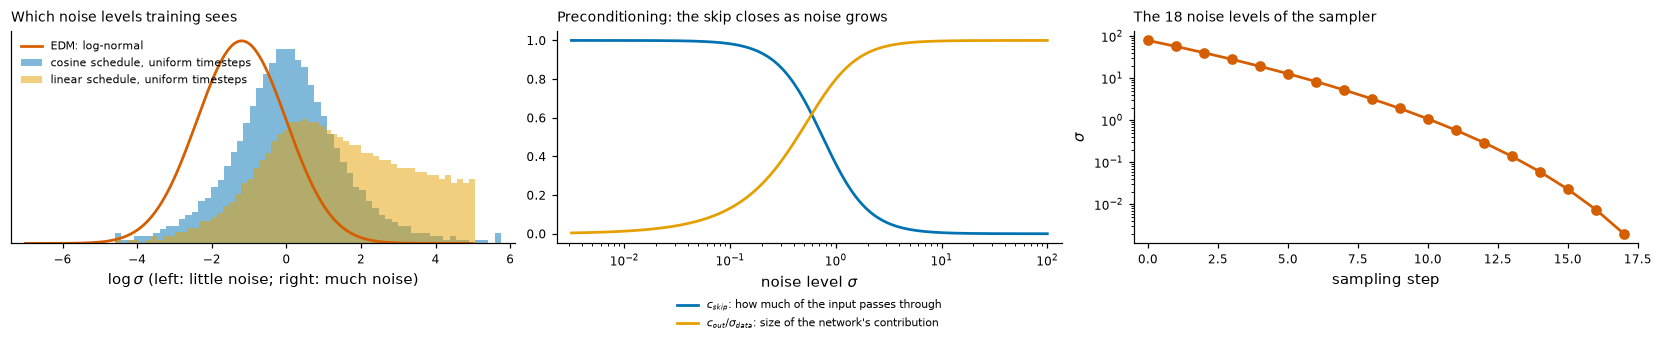

In [18]:
sigma_data = float(Xtr.std())
for label, pc in (("EDM, preconditioned", True), ("EDM, network outputs the clean image", False)):
    run(label, D.EDM(precondition=pc, sigma_data=sigma_data))
rows = {}
for label in ("EDM, preconditioned", "EDM, network outputs the clean image"):
    for steps, heun in ((18, True), (35, False), (9, True), (17, False)):
        r = RUNS[label]; x = r["diff"].sample(r["model"], LABELS, steps=steps, heun=heun); nfe = 2 * steps - 1 if heun else steps
        rows[(label, f"{'Heun' if heun else 'Euler'}, {nfe} evaluations")] = {k: v for k, v in score(x, f"{label} ({'Heun' if heun else 'Euler'}, {nfe} evaluations)", nfe, labels=LABELS).items() if k in COLS}
display(pd.DataFrame(rows).T.round(2))
print(f"standard deviation of the data: {sigma_data:.2f}")

edm = RUNS["EDM, preconditioned"]["diff"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
ls = np.linspace(-7, 5, 300)
axes[0].plot(ls, np.exp(-0.5 * ((ls - edm.p_mean) / edm.p_std) ** 2) / (edm.p_std * math.sqrt(2 * math.pi)), color=viz.VERMILION, label="EDM: log-normal")
axes[0].hist(-0.5 * torch.log(D.Diffusion("cosine").snr).numpy(), bins=60, density=True, color=viz.BLUE, alpha=0.5, label="cosine schedule, uniform timesteps")
axes[0].hist(-0.5 * torch.log(D.Diffusion("linear").snr).numpy(), bins=60, density=True, color=viz.ORANGE, alpha=0.5, label="linear schedule, uniform timesteps")
axes[0].set_xlabel(r"$\log \sigma$ (left: little noise; right: much noise)"); axes[0].set_yticks([]); axes[0].set_title("Which noise levels training sees", fontsize=9); axes[0].legend(fontsize=7, loc="upper left")
s = torch.logspace(-2.5, 2, 200)
axes[1].plot(s, sigma_data ** 2 / (s ** 2 + sigma_data ** 2), color=viz.BLUE, label=r"$c_{skip}$: how much of the input passes through")
axes[1].plot(s, s * sigma_data / (s ** 2 + sigma_data ** 2).sqrt() / sigma_data, color=viz.ORANGE, label=r"$c_{out}/\sigma_{data}$: size of the network's contribution")
axes[1].set_xscale("log"); axes[1].set_xlabel(r"noise level $\sigma$"); axes[1].set_title("Preconditioning: the skip closes as noise grows", fontsize=9); axes[1].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.22))
axes[2].plot(range(18), edm.sigmas(18)[:-1], "o-", color=viz.VERMILION); axes[2].set_yscale("log"); axes[2].set_xlabel("sampling step"); axes[2].set_ylabel(r"$\sigma$")
axes[2].set_title("The 18 noise levels of the sampler", fontsize=9)
plt.show()

**What happened.**

* **Preconditioning did not help here. It hurt**: FD 25.8 with it and 7.7 without (Heun, 35 evaluations). This
  agrees with section 5. At low noise the preconditioned network predicts a noise-like correction, and in our
  setting networks that do so finish their samples badly. The results of [Karras et al., 2022](https://arxiv.org/abs/2206.00364) were obtained with large
  U-Nets on real images, and nothing here contradicts them at that scale. (The run above sets $\sigma_{\text{data}}$ to the measured standard
  deviation of our data, 0.75. In a development run with the paper's value of 0.5 the preconditioned model reached
  FD 16.6: better, and still far from 7.7. That run is not part of this notebook.)
* **The second-order sampler helps the preconditioned model** at equal cost (25.8 against 30.3 with 35
  evaluations, 19.0 against 33.8 with 17) and makes no consistent difference to the other model (7.7 against 8.0,
  and 9.4 against 8.7).
* **One result we cannot explain**: the preconditioned model is better with 17 evaluations (19.0) than with 35
  (25.8).
* **The EDM noise distribution with a clean-image output** (7.7) is as good as the cosine schedule with a
  clean-image output (8.5, with seeds up to 9.4).

What lasted from EDM is less any single setting than the organisation: noise level in place of timestep, and
schedule, target, weight and sampler as separate dials. The left panel shows one of those dials. Uniform timesteps
on the linear schedule spend much of training at very high noise, the cosine schedule less, and the log-normal
choice concentrates on the middle.

## 11. Putting the choices together: the base denoiser

We now combine what was measured: cosine schedule, the target and weight that did best in sections 5 and 6,
sinusoidal noise-level input, EMA weights, 10% label dropout. The network is widened from 128 to 256 units (1.1
million parameters). We train it for 3,000 steps and, separately, for 6,000 steps, and apply the memorisation
checks of section 5 to both.

For a fair comparison with notebook 06, whose models were all unconditional, we also train two **unconditional**
denoisers (the label is always dropped) at the small size used in the ablations: the recipe of section 2 with the
cosine schedule, and the final recipe.

,fd,precision,coverage,nn_ratio,judge_acc,nfe
model,,,,,,
real data,5.4,0.96,0.96,1.02,0.98,0
"DDPM recipe (linear schedule, predicts noise), 1,000 steps",30.3,0.90,0.83,0.98,0.99,1000
"cosine, noise",25.2,0.87,0.83,0.96,0.89,50
"cosine, noise, guidance 1",10.0,0.97,0.91,0.95,0.98,100
"cosine, clean image",8.5,0.97,0.95,0.91,0.97,50
"cosine, clean image, min-SNR",7.8,0.96,0.94,0.92,0.96,50
final recipe,7.0,0.95,0.94,0.87,0.97,50
"final recipe, 10 steps",7.8,0.97,0.94,0.88,0.98,10
"final recipe, guidance 1",7.6,0.98,0.93,0.87,1.00,100


training time: final recipe 25 s, 6,000 steps 50 s; 1,122,880 parameters
memorisation checks:


,nn_ratio,"training / held-out error, least noise","training / held-out error, most noise",median distance to nearest training image,samples within 0.5 of a training image
"cosine, clean image",0.91,0.77,0.98,1.79,0.0
final recipe,0.87,0.55,0.98,1.72,0.0
"final recipe, 6,000 steps",0.87,0.35,0.98,1.51,0.0


saved checkpoints/base_denoiser.pt


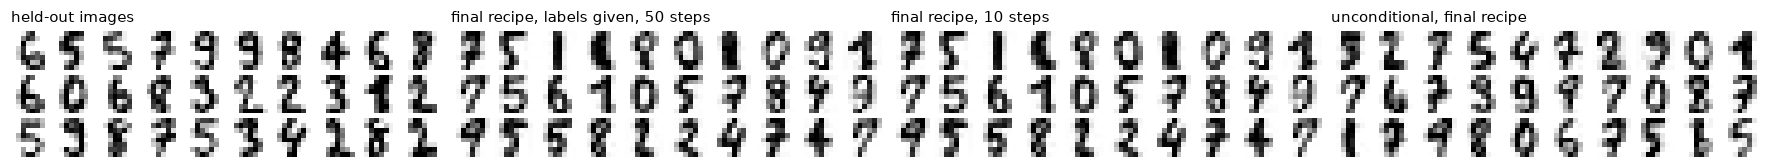

In [19]:
FINAL = dict(schedule="cosine", pred="x0", weighting="min-snr")
run("final recipe", D.Diffusion(**FINAL), width=256, steps=3000)
run("final recipe, 6,000 steps", D.Diffusion(**FINAL), width=256, steps=6000)
run("unconditional, predicts noise", D.Diffusion("cosine", "eps"), p_uncond=1.0)
run("unconditional, final recipe", D.Diffusion(**FINAL), p_uncond=1.0)
for n in ("final recipe", "final recipe, 6,000 steps"):
    report(n); report(n, row=n + ", guidance 1", w=1.0); report(n, row=n + ", 10 steps", steps=10)
for n in ("unconditional, predicts noise", "unconditional, final recipe"):
    score(sample(n, labels=NO_LABEL), n, nfe=50)
shown = ["real data", "DDPM recipe (linear schedule, predicts noise), 1,000 steps", "cosine, noise", "cosine, noise, guidance 1", "cosine, clean image", "cosine, clean image, min-SNR",
         "final recipe", "final recipe, 10 steps", "final recipe, guidance 1", "final recipe, 6,000 steps", "unconditional, predicts noise", "unconditional, final recipe"]
display(table(shown))
print(f"training time: final recipe {RUNS['final recipe']['seconds']:.0f} s, 6,000 steps {RUNS['final recipe, 6,000 steps']['seconds']:.0f} s; {RUNS['final recipe']['params']:,} parameters")
print("memorisation checks:")
display(pd.DataFrame({n: memorisation(n) for n in ("cosine, clean image", "final recipe", "final recipe, 6,000 steps")}).T.round(2))

torch.save(dict(state=RUNS["final recipe"]["model"].state_dict(), config=dict(width=256, depth=3, time="sinusoidal", **FINAL)), os.path.join(CKPT_DIR, "base_denoiser.pt"))
print("saved checkpoints/base_denoiser.pt")

fig, axes = plt.subplots(1, 4, figsize=(16, 2.4))
for ax, (title, x) in zip(axes, [("held-out images", Xte), ("final recipe, labels given, 50 steps", sample("final recipe")), ("final recipe, 10 steps", sample("final recipe", steps=10)),
                                 ("unconditional, final recipe", sample("unconditional, final recipe", labels=NO_LABEL))]):
    images.show_grid(x[:30], nrow=10, ax=ax, title=title)
plt.show()

**What happened.**

* **The final recipe** (cosine schedule, clean-image target, min-SNR weight, labels given) reaches FD 7.0, with
  precision 0.95 and coverage 0.94. Real data score 5.4, 0.96 and 0.96. With 10 sampling steps it still reaches
  7.8.
* **Guidance adds little to it** (7.6 at $w = 1$). Challenge 1 looks at other scales.
* **Longer training buys memorisation.** After 6,000 steps FD is 6.5. But the denoising error on training images,
  relative to held-out images at the lowest noise level, has fallen from 0.55 to 0.35, and samples lie at a median
  distance of 1.51 from the nearest training image where held-out images lie at 2.07. There are still no near
  copies. With 1,438 images, more training mostly moves the model towards its training set, so the 3,000-step
  model is the one we save as the base denoiser. Note that its ratio (0.55) is already lower than that of the
  smaller network of section 5 (0.77): width also buys memorisation.
* **The fair comparison with notebook 06** is the pair of unconditional models. With the noise-predicting recipe
  the unconditional denoiser reaches FD 46.9, precision 0.71 and coverage 0.64: *worse* on FD than the WGAN-GP
  (13.8) and the pixel model (14.6). With the final recipe it reaches FD 12.3, precision 0.94 and coverage 0.90,
  with an nn_ratio of 0.96. The best of notebook 06 on precision and coverage was the pixel model, at 0.82 and
  0.72.

At our budget, then, diffusion did not beat the older families because it is diffusion. It beat them after the
choices of this notebook were made well, and one of those choices went against the usual default.

## 12. Scorecard

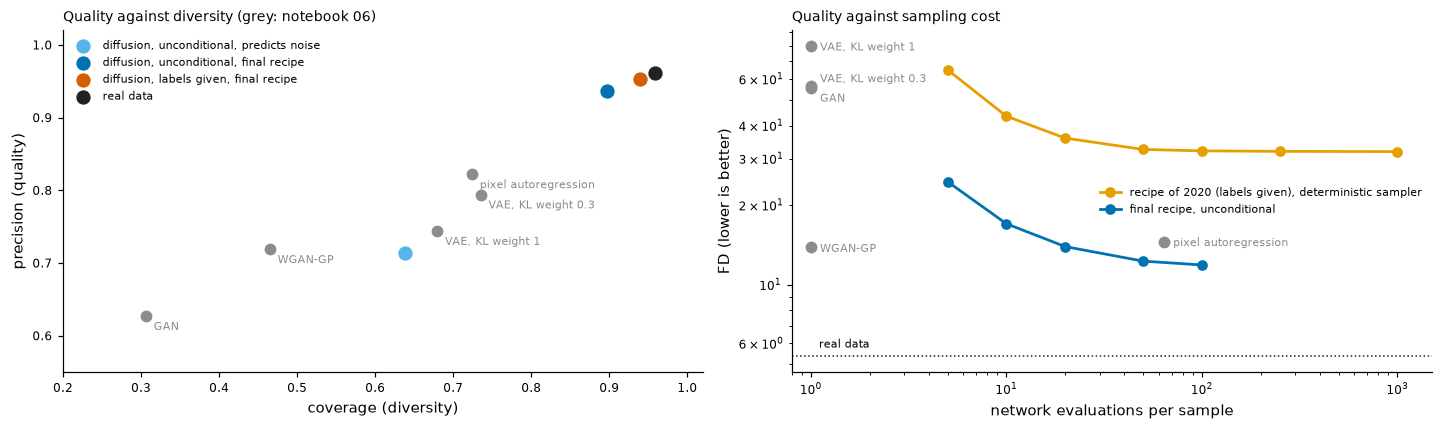

final recipe, unconditional: FD by number of sampling steps {5: 24.5, 10: 17.0, 20: 13.9, 50: 12.3, 100: 11.9}


In [20]:
uncond = ["unconditional, predicts noise", "unconditional, final recipe"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
for name, r in nb06.iterrows():
    if name in ("real data", "autoencoder, codes from N(0, 1)"):
        continue
    ax.scatter(r["coverage"], r["precision"], s=45, color=viz.GREY, zorder=2); ax.annotate(name.split(", median")[0], (r["coverage"], r["precision"]), textcoords="offset points", xytext=(5, -9), fontsize=7, color=viz.GREY)
for name, col, label in ((uncond[0], viz.SKY, "diffusion, unconditional, predicts noise"), (uncond[1], viz.BLUE, "diffusion, unconditional, final recipe"), ("final recipe", viz.VERMILION, "diffusion, labels given, final recipe")):
    ax.scatter(ROWS[name]["coverage"], ROWS[name]["precision"], s=70, color=col, zorder=3, label=label)
ax.scatter(ROWS["real data"]["coverage"], ROWS["real data"]["precision"], s=70, color=viz.BLACK, zorder=3, label="real data")
ax.set_xlim(0.2, 1.02); ax.set_ylim(0.55, 1.02); ax.set_xlabel("coverage (diversity)"); ax.set_ylabel("precision (quality)"); ax.set_title("Quality against diversity (grey: notebook 06)", fontsize=9); ax.legend(fontsize=7, loc="upper left")
ax = axes[1]
for name, r in nb06.iterrows():
    if name in ("real data", "autoencoder, codes from N(0, 1)"):
        continue
    ax.scatter(r["nfe"], r["fd"], s=45, color=viz.GREY, zorder=2)
    ax.annotate(name.split(", median")[0], (r["nfe"], r["fd"]), textcoords="offset points", xytext=(6, {"GAN": -10, "VAE, KL weight 0.3": 4}.get(name.split(", median")[0], -3)), fontsize=7, color=viz.GREY)
d = steps_table[steps_table.sampler == "deterministic (DDIM)"]
ax.plot(d.steps, d.fd, "o-", color=viz.ORANGE, label="recipe of 2020 (labels given), deterministic sampler")
fd_steps = {s: report("unconditional, final recipe", steps=s, keep=False, labels=NO_LABEL)["fd"] for s in (5, 10, 20, 50, 100)}
ax.plot(list(fd_steps), list(fd_steps.values()), "o-", color=viz.BLUE, label="final recipe, unconditional")
ax.axhline(ROWS["real data"]["fd"], color=viz.BLACK, ls=":", lw=1); ax.text(1.1, ROWS["real data"]["fd"] * 1.08, "real data", fontsize=7)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.8, 1500); ax.set_xlabel("network evaluations per sample"); ax.set_ylabel("FD (lower is better)"); ax.set_title("Quality against sampling cost", fontsize=9); ax.legend(fontsize=7, loc="center right")
plt.show()
print("final recipe, unconditional: FD by number of sampling steps", {s: round(v, 1) for s, v in fd_steps.items()})

keep = ["real data", "DDPM recipe (linear schedule, predicts noise), 1,000 steps", "cosine, noise", "cosine, clean image", "cosine, v", "cosine, noise, guidance 1",
        "final recipe", "final recipe, 10 steps", "final recipe, guidance 1", "unconditional, predicts noise", "unconditional, final recipe"]
rows = [dict(model=n, family="image", **{k: ROWS[n].get(k) for k in ("fd", "precision", "coverage", "nn_ratio", "judge_acc", "nfe")}) for n in keep]
metrics.append_rows(rows, "07_diffusion");

**Reading the scorecard.**

* **Left.** The grey points are the models of notebook 06. The unconditional diffusion model with the final recipe
  is close to real data on both axes. The unconditional model that predicts noise sits among the grey points.
* **Right.** Quality against the cost of sampling. The unconditional final recipe reaches FD 24.5 with 5 network
  evaluations, 17.0 with 10, 13.9 with 20 and 12.3 with 50. At 20 evaluations it matches the FD of the pixel model
  (14.6 with 64 evaluations) and of the WGAN-GP (13.8), with far better precision and coverage.
* **What remains.** The WGAN-GP needs one evaluation. Diffusion needs ten or more, and with guidance twice that.
  Reducing the number of steps by distillation is a post-training subject and is covered in the post-training
  series.

Two limits of this notebook. The backbone is an MLP that sees the image as 64 unrelated numbers; notebook 09
replaces it with a transformer over patches. And the model works on pixels; notebook 08 pretrains the encoders
and the autoencoder that let diffusion run in a compressed space and take text as its condition.

## 13. Design choices: what changed, and the recipes of well-known models

| Choice | Original (2020) | Moved to | Why | Measured here |
|---|---|---|---|---|
| Sampler | 1,000 steps with fresh noise | Deterministic, 20 to 50 steps ([Song et al., 2020](https://arxiv.org/abs/2010.02502)); higher-order solvers ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)) | The network does not depend on the sampler | One model: 50 deterministic steps FD 32.5; 1,000 original steps 30.3; 10 steps 43.4 |
| Noise schedule | Linear | Cosine ([Nichol & Dhariwal, 2021](https://arxiv.org/abs/2102.09672)); zero terminal SNR ([Lin et al., 2023](https://arxiv.org/abs/2305.08891)) | Do not waste timesteps on pure noise; train on what sampling starts from | Cosine 25.2 against linear 32.5. Zero terminal SNR: 29.2 against 30.5, no clear effect at 8×8. A schedule stopped at SNR 0.52: 111.9 |
| Target | Noise | $v$ ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)); preconditioning ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)); the clean image again ([Li & He, 2025](https://arxiv.org/abs/2511.13720)) | Noise prediction is degenerate at high noise | Clean image 8.5, noise 25.2, $v$ 30.6; preconditioning 25.8 against 7.7 without. The advantage lies mostly in the last sampling steps |
| Loss weight | Whatever the target implies | Chosen directly: min-SNR ([Hang et al., 2023](https://arxiv.org/abs/2303.09556)), the view of [Kingma et al., 2021](https://arxiv.org/abs/2107.00630) | Noise levels compete for the network | min-SNR: noise 25.2 to 20.2, $v$ 30.6 to 22.8, clean image 8.5 to 7.8 (inside the seed range) |
| Noise-level input | Sinusoidal features | Unchanged in most models; questioned by [Sun et al., 2025](https://arxiv.org/abs/2502.13129) | The input already reveals its noise level | With no noise-level input: FD 78.9 when predicting noise, 9.7 when predicting the clean image. One number was as good as sinusoidal features |
| Weights used for sampling | EMA | Unchanged | The loss is noisy | Constant learning rate: 30.0 with EMA, 41.7 without. Rate decayed to zero: 25.2 against 24.8 |
| Conditioning | None; then a separate classifier to steer sampling | Label dropout and classifier-free guidance ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)) | One network, one dial for fidelity against diversity | Scale 1: FD 25.2 to 10.0, judge's accuracy 0.89 to 0.98. Scale 4: coverage 0.79. Without dropout the gain varied with the seed (FD 7.2 to 16.2) |

**The recipes of some well-known models**, as published in their papers and released code.

| Model | Schedule | Target | Sampler and steps | Guidance |
|---|---|---|---|---|
| DDPM ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)) | Linear, 1,000 steps | Noise | Ancestral, 1,000 | None |
| Improved DDPM ([Nichol & Dhariwal, 2021](https://arxiv.org/abs/2102.09672)) | Cosine | Noise, with learned variances | Ancestral, fewer steps | None |
| Latent diffusion / Stable Diffusion 1 ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) | Scaled linear, in the latent space of an autoencoder | Noise | Deterministic (DDIM), 50 to 200 steps | Classifier-free |
| EDM ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)) | Log-normal noise levels | Preconditioned denoiser | Heun, 18 to 40 steps | Optional |
| Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) | Straight path between data and noise (notebook 09) | Velocity | Euler | Classifier-free |

Every row after the first keeps the idea of section 2 and changes the choices this notebook varied.

## Challenge Problem 1: Does guidance still help the final recipe?

Section 9 measured guidance on the noise-predicting model of the ablations. Sample the final model (`"final recipe"`) at guidance scales 0, 0.5, 1, 2 and 4
with `report(..., keep=False)` and tabulate FD, precision, coverage, nn_ratio and the judge's accuracy. Does guidance improve the final model as much as
it improved the earlier one? What does it do to nn_ratio?

In [21]:
# Start your code here

### Challenge Problem 1 Solution

In [22]:
g = pd.DataFrame({w: {k: v for k, v in report("final recipe", w=w, keep=False).items() if k in COLS} for w in (0.0, 0.5, 1.0, 2.0, 4.0)}).T
g.index.name = "guidance scale"
display(g.round(2))
# Read the table. Guidance helps the final model much less than it helped the noise-predicting model of section 9.
# FD goes from 7.0 to 6.6 at a scale of 0.5, a difference no larger than that between two seeds, and then gets worse:
# 7.6, 9.5 and 11.3 at scales 1, 2 and 4. What guidance still does: the judge's accuracy rises from 0.97 to 1.00 and
# precision from 0.95 to 0.99 at a scale of 0.5, and coverage falls from 0.94 to 0.84 at a scale of 4.
# nn_ratio stays between 0.87 and 0.90, so guidance does not move the samples towards the training set.
# A reading: guidance repairs a weak conditional model. The earlier model produced the requested digit 89% of the
# time and had much to gain. The final model does so 97% of the time and has little left to repair.

,fd,precision,coverage,nn_ratio,nfe,judge_acc
guidance scale,,,,,,
0.0,6.99,0.95,0.94,0.87,50.0,0.97
0.5,6.61,0.99,0.96,0.87,100.0,1.00
1.0,7.63,0.98,0.93,0.87,100.0,1.00
2.0,9.46,0.98,0.90,0.88,100.0,1.00
4.0,11.27,0.95,0.84,0.90,100.0,0.99


## Challenge Problem 2: A deterministic sampler is a map from noise to images

With $\eta = 0$ the sampler has no randomness after the first draw: each starting noise $x_T$ is mapped to one image. Take two starting noises $a$ and
$b$ and eleven points between them on the great circle, $x_T(\lambda) = \cos(\lambda\pi/2)\,a + \sin(\lambda\pi/2)\,b$ (a straight line would pass
through points with too little variance). Sample each with the final model and the label 3, using `x_T=` in `diff.sample`. Then repeat with the label
changing from 3 to 8 half way and the noise fixed. What changes smoothly, and what jumps?

In [23]:
# Start your code here

### Challenge Problem 2 Solution

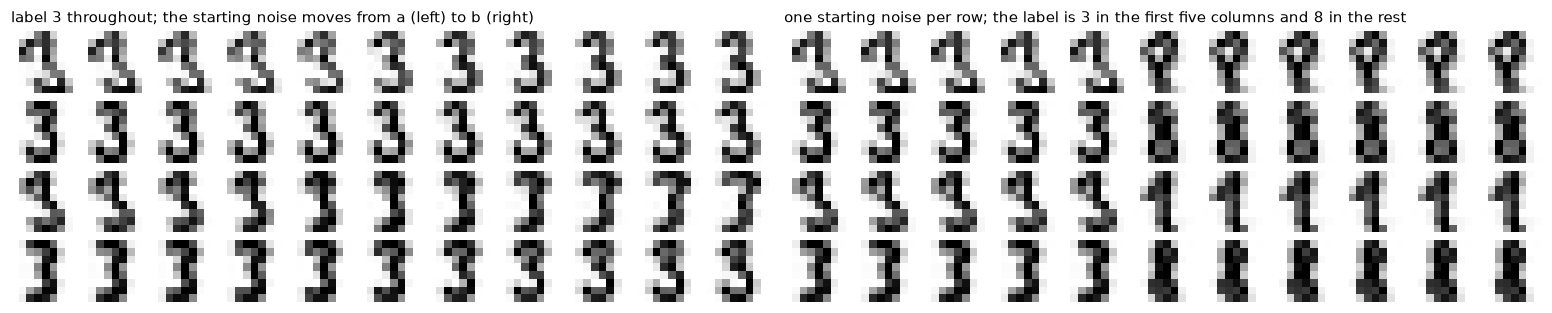

distance between neighbouring images along the path, mean over the four rows: [0.45 0.67 0.73 0.84 1.11 0.71 0.65 0.56 0.52 0.47]
distance between the two ends: 4.68
the judge reads 0.98 of the 44 images on the paths as a 3
label switch: the judge reads 1.00 of the first five columns as a 3 and 0.50 of the rest as an 8
label switch: distance between columns 5 and 6 4.72; between two images with the same label and noise 0.00


In [24]:
diff, model = RUNS["final recipe"]["diff"], RUNS["final recipe"]["model"]
g = torch.Generator().manual_seed(3)
a, b = torch.randn(4, 64, generator=g), torch.randn(4, 64, generator=g)
lam = torch.linspace(0, 1, 11)
paths = torch.stack([torch.cos(l * math.pi / 2) * a + torch.sin(l * math.pi / 2) * b for l in lam], 1).reshape(-1, 64)      # 4 rows of 11 starting noises
walk = diff.sample(model, torch.full((44,), 3), steps=50, x_T=paths)
same_noise = a[:, None].expand(4, 11, 64).reshape(-1, 64)
switch = diff.sample(model, torch.tensor(([3] * 5 + [8] * 6) * 4), steps=50, x_T=same_noise)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
images.show_grid(walk, nrow=11, ax=axes[0], title="label 3 throughout; the starting noise moves from a (left) to b (right)")
images.show_grid(switch, nrow=11, ax=axes[1], title="one starting noise per row; the label is 3 in the first five columns and 8 in the rest")
plt.show()
step = (walk.view(4, 11, 64)[:, 1:] - walk.view(4, 11, 64)[:, :-1]).norm(dim=-1)
print("distance between neighbouring images along the path, mean over the four rows:", np.round(step.mean(0).numpy(), 2))
print(f"distance between the two ends: {float((walk.view(4, 11, 64)[:, -1] - walk.view(4, 11, 64)[:, 0]).norm(dim=-1).mean()):.2f}")
with torch.no_grad():
    print(f"the judge reads {float((judge(walk).argmax(1) == 3).float().mean()):.2f} of the 44 images on the paths as a 3")
    sw_ = switch.view(4, 11, 64)
    print(f"label switch: the judge reads {float((judge(sw_[:, :5].reshape(-1, 64)).argmax(1) == 3).float().mean()):.2f} of the first five columns as a 3 and {float((judge(sw_[:, 5:].reshape(-1, 64)).argmax(1) == 8).float().mean()):.2f} of the rest as an 8")
    print(f"label switch: distance between columns 5 and 6 {float((sw_[:, 5] - sw_[:, 4]).norm(dim=-1).mean()):.2f}; between two images with the same label and noise 0.00")
# Read the output. Along the path between two starting noises the image changes gradually. Neighbouring images are
# 0.45 to 1.11 apart, while the two ends are 4.68 apart, and the judge reads 0.98 of the 44 images as a 3. The map
# from noise to image is continuous: nearby noises give nearby images. This is why a fixed starting noise (a "seed")
# reproduces an image, and why small changes to it give variations.
# Changing the label with the noise fixed is a jump: columns 5 and 6 are 4.72 apart, as far as two unrelated threes.
# Every image with the label 3 is read as a 3. Only half of those with the label 8 are read as an 8, which with four
# starting noises means two of the four rows; over 359 samples the same model produces the requested digit 97% of the
# time (section 11), so four rows are too few to conclude anything about eights.

## Final summary

* **The idea.** Noise an image in small steps and train a network to undo the noise. Training is a plain regression.
  Sampling applies the network repeatedly, starting from noise.
* **Sampler.** The trained network does not depend on the sampler. Fifty deterministic steps came within about 2
  FD of 1,000 steps of the original sampler.
* **Schedule.** The cosine schedule beat the linear one (FD 25.2 against 32.5) by not spending timesteps on pure
  noise. Zero terminal SNR had no clear effect at 8×8, and a calculation says why: the leak it removes is hidden by
  the noise at low resolution.
* **Target.** Predicting the clean image beat predicting the noise or $v$ by a factor of three in FD, against the
  default of 2020. Swapping networks during sampling located most of the advantage in the last, low-noise steps.
  The same result appeared in the EDM formulation, where preconditioning hurt.
* **Weight.** min-SNR helped the noise and $v$ networks and converged faster. It did not close the gap between
  targets: a target is more than a loss weight.
* **Noise-level input.** Essential when predicting noise, nearly irrelevant when predicting the clean image.
* **EMA.** Needed at a constant learning rate (FD 30.0 against 41.7), redundant when the rate decays to zero.
* **Guidance.** The largest single gain for the weaker model (FD 25.2 to 10.0) and a trade of diversity for
  fidelity at high scales. Label dropout is what makes it dependable.
* **Memorisation.** With 1,438 training images every model had begun to fit the training images at low noise, and
  wider networks and longer training went further. No model produced copies. A low FD alone would not have shown
  this.
* **Against notebook 06.** An unconditional denoiser with the recipe of 2020 lost to the WGAN-GP and the pixel
  model on FD. With the final recipe it reached precision 0.94 and coverage 0.90, where no earlier model passed
  0.82 and 0.74.
* **Next.** Notebook 08 pretrains the parts that surround a modern diffusion model: a vision encoder, a
  text-image model and the autoencoder for latent diffusion.

## References

* Jascha Sohl-Dickstein, Eric A. Weiss, Niru Maheswaranathan et al. (2015). **Deep Unsupervised Learning using Nonequilibrium Thermodynamics**. arXiv:1503.03585. [arxiv.org/abs/1503.03585](https://arxiv.org/abs/1503.03585)
* Yang Song, Stefano Ermon (2019). **Generative Modeling by Estimating Gradients of the Data Distribution**. arXiv:1907.05600. [arxiv.org/abs/1907.05600](https://arxiv.org/abs/1907.05600)
* Jonathan Ho, Ajay Jain, Pieter Abbeel (2020). **Denoising Diffusion Probabilistic Models**. arXiv:2006.11239. [arxiv.org/abs/2006.11239](https://arxiv.org/abs/2006.11239)
* Yang Song, Jascha Sohl-Dickstein, Diederik P. Kingma et al. (2020). **Score-Based Generative Modeling through Stochastic Differential Equations**. arXiv:2011.13456. [arxiv.org/abs/2011.13456](https://arxiv.org/abs/2011.13456)
* Jiaming Song, Chenlin Meng, Stefano Ermon (2020). **Denoising Diffusion Implicit Models**. arXiv:2010.02502. [arxiv.org/abs/2010.02502](https://arxiv.org/abs/2010.02502)
* Alex Nichol, Prafulla Dhariwal (2021). **Improved Denoising Diffusion Probabilistic Models**. arXiv:2102.09672. [arxiv.org/abs/2102.09672](https://arxiv.org/abs/2102.09672)
* Diederik P. Kingma, Tim Salimans, Ben Poole et al. (2021). **Variational Diffusion Models**. arXiv:2107.00630. [arxiv.org/abs/2107.00630](https://arxiv.org/abs/2107.00630)
* Tim Salimans, Jonathan Ho (2022). **Progressive Distillation for Fast Sampling of Diffusion Models**. arXiv:2202.00512. [arxiv.org/abs/2202.00512](https://arxiv.org/abs/2202.00512)
* Jonathan Ho, Tim Salimans (2022). **Classifier-Free Diffusion Guidance**. arXiv:2207.12598. [arxiv.org/abs/2207.12598](https://arxiv.org/abs/2207.12598)
* Tero Karras, Miika Aittala, Timo Aila et al. (2022). **Elucidating the Design Space of Diffusion-Based Generative Models**. arXiv:2206.00364. [arxiv.org/abs/2206.00364](https://arxiv.org/abs/2206.00364)
* Tiankai Hang, Shuyang Gu, Chen Li et al. (2023). **Efficient Diffusion Training via Min-SNR Weighting Strategy**. arXiv:2303.09556. [arxiv.org/abs/2303.09556](https://arxiv.org/abs/2303.09556)
* Shanchuan Lin, Bingchen Liu, Jiashi Li et al. (2023). **Common Diffusion Noise Schedules and Sample Steps are Flawed**. arXiv:2305.08891. [arxiv.org/abs/2305.08891](https://arxiv.org/abs/2305.08891)
* Robin Rombach, Andreas Blattmann, Dominik Lorenz et al. (2021). **High-Resolution Image Synthesis with Latent Diffusion Models**. arXiv:2112.10752. [arxiv.org/abs/2112.10752](https://arxiv.org/abs/2112.10752)
* Patrick Esser, Sumith Kulal, Andreas Blattmann et al. (2024). **Scaling Rectified Flow Transformers for High-Resolution Image Synthesis**. arXiv:2403.03206. [arxiv.org/abs/2403.03206](https://arxiv.org/abs/2403.03206)
* Tianhong Li, Kaiming He (2025). **Back to Basics: Let Denoising Generative Models Denoise**. arXiv:2511.13720. [arxiv.org/abs/2511.13720](https://arxiv.org/abs/2511.13720)
* Qiao Sun, Zhicheng Jiang, Hanhong Zhao et al. (2025). **Is Noise Conditioning Necessary for Denoising Generative Models?**. arXiv:2502.13129. [arxiv.org/abs/2502.13129](https://arxiv.org/abs/2502.13129)
* Nicholas Carlini, Jamie Hayes, Milad Nasr et al. (2023). **Extracting Training Data from Diffusion Models**. arXiv:2301.13188. [arxiv.org/abs/2301.13188](https://arxiv.org/abs/2301.13188)
* Zahra Kadkhodaie, Florentin Guth, Eero P. Simoncelli et al. (2023). **Generalization in diffusion models arises from geometry-adaptive harmonic representations**. arXiv:2310.02557. [arxiv.org/abs/2310.02557](https://arxiv.org/abs/2310.02557)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).